# Neural ODE per il sistema di Lorenz

L'obiettivo di questo notebook è addestrare una Neural ODE che modellizzi il sistema di Lorenz, studiato nei capitoli precedenti:
$$
\begin{cases}
\dot x = \sigma\,(y - x) \\
\dot y = x\,(r - z) - y \\
\dot z = x\,y - b\,z
\end{cases}
$$
con i parametri scelti da Lorenz nel lavoro originale (*Deterministic Nonperiodic Flow*, 1963):
$$
\sigma = 10, \qquad r = 28, \qquad b = \tfrac{8}{3}
$$
(nel codice `SIGMA`, `RHO`, `BETA`). Per questi valori il sistema ammette un attrattore strano. Inoltre, la divergenza del campo è costante e vale
$$
\nabla\cdot F = -(\sigma + 1 + b) \approx -13.667 .
$$

Una loss bassa sulle traiettorie di test non garantisce che la rete abbia appreso la dinamica caotica: indica solo che, su orizzonti brevi, le traiettorie predette restano vicine a quelle vere. Per questo la rete addestrata viene valutata anche in modo quantitativo, calcolando gli invarianti dinamici del flusso appreso e confrontandoli con quelli del sistema di Lorenz, ottenuti nello stesso notebook con lo stesso metodo:

- lo spettro di Lyapunov $\mu_1 \ge \mu_2 \ge \mu_3$ (valori di riferimento $\mu_1 \approx 0.905$, $\mu_2 = 0$, $\mu_3 \approx -14.57$);
- la dimensione di Kaplan–Yorke $D_{KY} = 2 + \mu_1/|\mu_3| \approx 2.06$;
- il tempo di Lyapunov $t_L = 1/\mu_1$;
- la somma degli esponenti, che deve coincidere con la divergenza media del campo, $\sum_i \mu_i = \langle \nabla\cdot F \rangle$.

La rete è addestrata su più traiettorie con condizioni iniziali casuali; lo spettro è calcolato a partire da più condizioni iniziali, per verificare che non dipenda da esse, come previsto dall'ipotesi di ergodicità.

In [86]:
import time
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from torchdiffeq import odeint                      # backpropagation standard (solo per il confronto dei gradienti)
from torchdiffeq import odeint_adjoint              # metodo aggiunto (usato per l'addestramento se ADJOINT = True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


## Parametri

In [87]:
# Sistema di Lorenz
SIGMA, RHO, BETA = 10.0, 28.0, 8.0 / 3.0

# Traiettorie di addestramento
N_TRAJ = 25                                   # numero di traiettorie
SEED_DATI = 0                                # seme per le condizioni iniziali

# Griglia temporale
DT = 0.004            # passo di campionamento 
T_TRANSIENT = 0     # tempo scartato all'inizio di ogni traiettoria (0 = transitorio tenuto nei dati)
T_DATA_TOT = 40.0     # durata totale dei dati
T_DATA = T_DATA_TOT / N_TRAJ   # durata di ciascuna traiettoria

# Split
SPLIT = 'traiettorie'               # 'traiettorie': traiettorie intere in val/test | 'cronologico': 70/15/15 dentro ogni traiettoria
N_VAL_TRAJ, N_TEST_TRAJ = 2, 2      # usati con SPLIT = 'traiettorie'
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15   # usati con SPLIT = 'cronologico'

# Seme della rete: pesi iniziali e ordine dei batch (cambiarlo per ripetere l'addestramento)
SEED_RETE = 45
torch.manual_seed(SEED_RETE)
np.random.seed(SEED_RETE)

# Addestramento
SEQ_LENGTH = 100      # punti per finestra -> orizzonte (SEQ_LENGTH-1)*DT ≈ 1.0 (circa un tempo di Lyapunov)
BATCH_SIZE = 64
HIDDEN_DIM = 128
LR = 1e-3
L2_LAMBDA = 1e-4
EPOCHS = 80
PATIENCE = 30         # con 20 epoche l'early stopping non scatta: resta solo la scelta dell'epoca migliore
PRINT_EVERY = 1

# Metodo per il gradiente: True = metodo aggiunto (memoria costante), False = backpropagation standard
# attraverso il risolutore (stesso gradiente, vedi il controllo più sotto, ma circa 8 volte più veloce qui)
ADJOINT = False

# Risolutore (valori di default di torchdiffeq, resi espliciti)
METHOD = 'dopri5'
RTOL, ATOL = 1e-5, 1e-7               # integrazione in avanti
ADJ_RTOL, ADJ_ATOL = 1e-5, 1e-7       # integrazione all'indietro del sistema aggiunto

# Penalità sulla divergenza: per Lorenz div F = -(sigma + 1 + beta) in ogni punto
LAMBDA_DIV = 0.1                     # peso della penalità, costante per tutto l'addestramento (0 = nessuna penalità)
DIV_START = 1                         # epoca da cui la penalità è attiva (1 = da subito)
DIV_RAMP = 0                          # epoche di rampa da 0 a LAMBDA_DIV (0 = nessuna rampa: peso costante)
DIV_TARGET = -(SIGMA + 1 + BETA)      # -13.667

MODEL_PATH = 'neuralode_lorenz_tesi_best.pt'

### Scatola delle condizioni iniziali
Le condizioni iniziali delle traiettorie di addestramento si estraggono uniformemente in un parallelepipedo che contiene l'attrattore,
$$
[x_{\min}, x_{\max}] \times [y_{\min}, y_{\max}] \times [z_{\min}, z_{\max}],
$$
individuato dai due vertici opposti `BOX_LO` $= (x_{\min}, y_{\min}, z_{\min})$ e `BOX_HI` $= (x_{\max}, y_{\max}, z_{\max})$.

Lo si ricava da una traiettoria lunga di Lorenz, partendo da $(1,1,1)$: scartato il transitorio, per ogni coordinata si prendono il minimo e il massimo raggiunti e li si arrotonda verso l'esterno al multiplo di 10. Per l'ergodicità la traiettoria esplora tutto l'attrattore, quindi il risultato non dipende dalla condizione iniziale scelta.

In [88]:
def lorenz(t, s):
    return [SIGMA * (s[1] - s[0]), s[0] * (RHO - s[2]) - s[1], s[0] * s[1] - BETA * s[2]]

T_BOX, T_TRANS_BOX = 500.0, 50.0                 # durata utile e transitorio scartato
sol = solve_ivp(lorenz, (0, T_TRANS_BOX + T_BOX), [1.0, 1.0, 1.0],
                t_eval=np.arange(T_TRANS_BOX, T_TRANS_BOX + T_BOX, DT),
                method='DOP853', rtol=1e-10, atol=1e-12)
x_min, x_max = sol.y.min(axis=1), sol.y.max(axis=1)

BOX_LO = np.floor(x_min / 10) * 10               # arrotondamento verso l'esterno al multiplo di 10
BOX_HI = np.ceil(x_max / 10) * 10
print(f'attrattore:  min {x_min.round(1)}   max {x_max.round(1)}')
print(f'scatola:     BOX_LO = {BOX_LO}   BOX_HI = {BOX_HI}')

attrattore:  min [-19.  -26.1   2.7]   max [18.7 25.4 46.7]
scatola:     BOX_LO = [-20. -30.   0.]   BOX_HI = [20. 30. 50.]


## Dati
Per ogni condizione iniziale si integra la traiettoria vera con `solve_ivp` (DOP853, tolleranze strette). Ogni traiettoria viene poi divisa in modo cronologico in train / validazione / test; i tre insiemi sono le unioni dei pezzi corrispondenti delle 5 traiettorie. Con il transitorio tenuto, i tratti iniziali (fuori dall'attrattore) finiscono nel train, mentre validazione e test stanno nella parte finale di ogni traiettoria, sull'attrattore.

In [89]:
def lorenz_rhs(t, s, sigma=SIGMA, rho=RHO, beta=BETA):
    x, y, z = s
    return [sigma * (y - x), x * (rho - z) - y, x * y - beta * z]

def generate_lorenz_data(x0, dt, t_transient, t_data):
    n_total = int(round((t_transient + t_data) / dt)) + 1
    t_all = np.linspace(0.0, (n_total - 1) * dt, n_total)
    sol = solve_ivp(lorenz_rhs, (t_all[0], t_all[-1]), x0, t_eval=t_all,
                    method='DOP853', rtol=1e-10, atol=1e-12)
    n_tr = int(round(t_transient / dt))
    t = t_all[n_tr:] - t_all[n_tr]          # il tempo riparte da 0 dopo l'eventuale transitorio
    return t, sol.y.T[n_tr:]                 # shape (N, 3)

rng = np.random.default_rng(SEED_DATI)
X0S = rng.uniform(BOX_LO, BOX_HI, size=(N_TRAJ, 3))

trajs = []
for x0 in X0S:
    t_np, s = generate_lorenz_data(x0, DT, T_TRANSIENT, T_DATA)
    trajs.append(s)

N = len(t_np)
if SPLIT == 'cronologico':
    # 70/15/15 dentro ogni traiettoria
    n_train, n_val = int(TRAIN_FRAC * N), int(VAL_FRAC * N)
    train_list = [s[:n_train] for s in trajs]
    val_list   = [s[n_train:n_train + n_val] for s in trajs]
    test_list  = [s[n_train + n_val:] for s in trajs]
    ruolo = [['train', 'val', 'test']] * N_TRAJ
else:
    # traiettorie intere: le ultime N_VAL_TRAJ + N_TEST_TRAJ vanno in validazione e test
    n_tr_traj = N_TRAJ - N_VAL_TRAJ - N_TEST_TRAJ
    assert n_tr_traj >= 1, 'servono più traiettorie di N_VAL_TRAJ + N_TEST_TRAJ'
    train_list = trajs[:n_tr_traj]
    val_list   = trajs[n_tr_traj:n_tr_traj + N_VAL_TRAJ]
    test_list  = trajs[n_tr_traj + N_VAL_TRAJ:]
    ruolo = ['train'] * n_tr_traj + ['val'] * N_VAL_TRAJ + ['test'] * N_TEST_TRAJ

print('condizioni iniziali:\n', X0S.round(2))
print(f'{N_TRAJ} traiettorie da {N} punti ({T_DATA:.1f} u.t.) = {N_TRAJ * N} punti in tutto')
print(f'split {SPLIT!r}: punti di train {sum(map(len, train_list))} | val {sum(map(len, val_list))} | test {sum(map(len, test_list))}')
assert min(len(s) for s in val_list + test_list) >= SEQ_LENGTH, \
    'pezzi di validazione/test più corti di una finestra: aumentare T_DATA_TOT, ridurre N_TRAJ o SEQ_LENGTH'

# Normalizzazione con statistiche del SOLO train (tutte le traiettorie insieme)
train_all = np.concatenate(train_list)
mean = train_all.mean(axis=0)
std = train_all.std(axis=0)
normalize = lambda a: (a - mean) / std
denormalize = lambda a: a * std + mean

to_tensor = lambda a: torch.tensor(a, dtype=torch.float32, device=device)
train_n = [to_tensor(normalize(a)) for a in train_list]
val_n   = [to_tensor(normalize(a)) for a in val_list]
test_n  = [to_tensor(normalize(a)) for a in test_list]

condizioni iniziali:
 [[  5.48 -13.81   2.05]
 [-19.34  18.8   45.64]
 [  4.27  13.77  27.18]
 [ 17.4   18.95   0.14]
 [ 14.3  -27.98  36.48]
 [-12.97  21.79  27.07]
 [ -8.01  -4.64   1.42]
 [-15.03  10.24  32.36]
 [  4.62  -6.98  49.86]
 [ 19.23  11.13  32.52]
 [  7.54  -6.66   6.75]
 [  8.86   1.52  15.51]
 [ -0.57  23.37  46.7 ]
 [ -5.69   4.29  16.09]
 [  3.77  -9.73  19.58]
 [ 15.61 -16.37  31.16]
 [-16.64  19.96  39.35]
 [-10.43  22.59   2.93]
 [ -6.56 -20.98  22.52]
 [ 11.85 -16.16   2.6 ]
 [ -3.82 -18.09   4.54]
 [  3.21 -12.08  33.6 ]
 [-12.02  26.53  18.26]
 [-15.78   7.75  46.36]
 [ -2.38  27.28  24.99]]
25 traiettorie da 401 punti (1.6 u.t.) = 10025 punti in tutto
split 'traiettorie': punti di train 8421 | val 802 | test 802


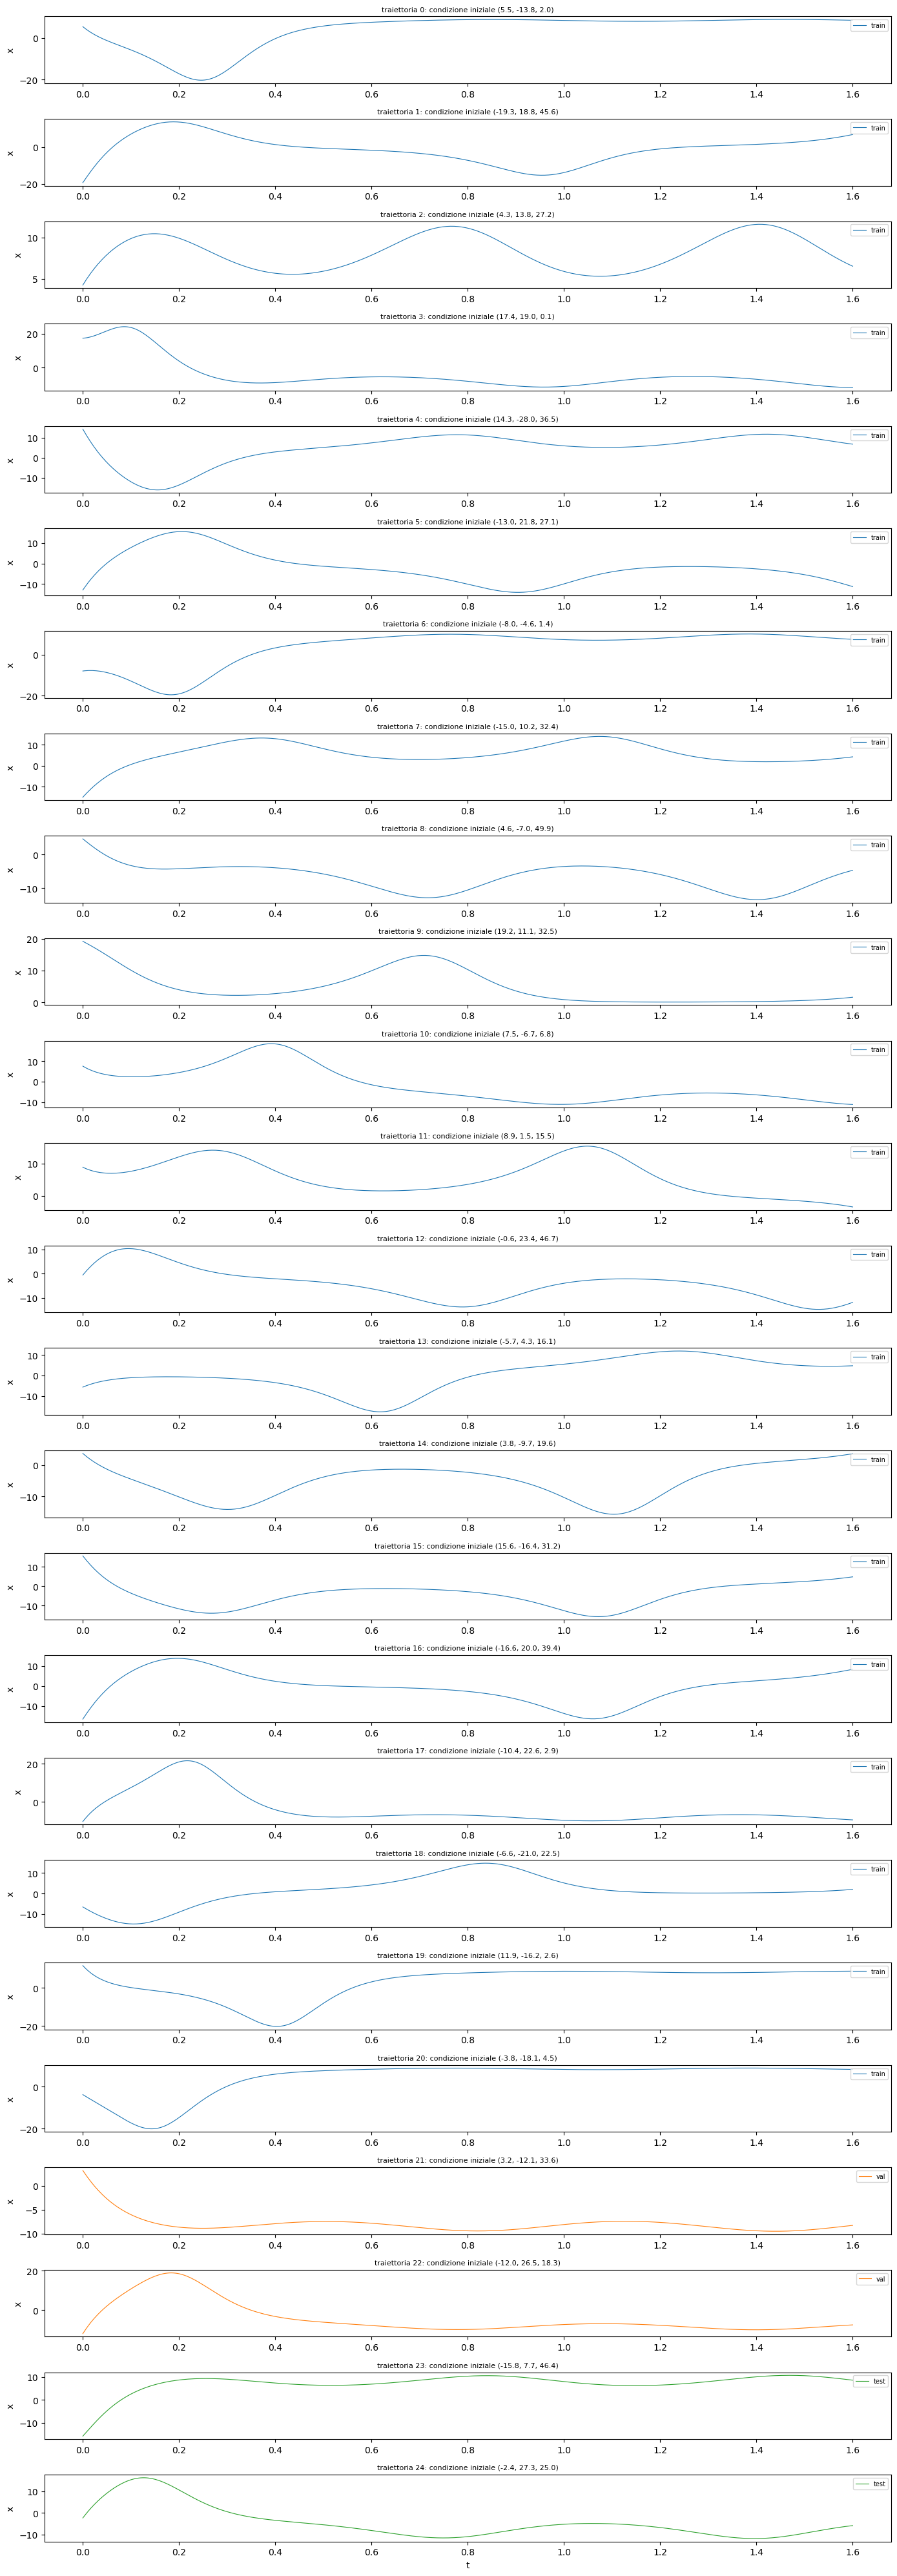

In [90]:
colori = {'train': 'tab:blue', 'val': 'tab:orange', 'test': 'tab:green'}
fig = plt.figure(figsize=(14, 1.6 * N_TRAJ))
for k, s in enumerate(trajs):
    ax = fig.add_subplot(N_TRAJ, 1, k + 1)
    if SPLIT == 'cronologico':
        i1, i2 = n_train, n_train + n_val
        for (a, b), r in zip([(0, i1), (i1, i2), (i2, N)], ['train', 'val', 'test']):
            ax.plot(t_np[a:b], s[a:b, 0], lw=0.8, color=colori[r], label=r)
    else:
        ax.plot(t_np, s[:, 0], lw=0.8, color=colori[ruolo[k]], label=ruolo[k])
    ax.set_ylabel('x')
    ax.set_title(f'traiettoria {k}: condizione iniziale ({X0S[k, 0]:.1f}, {X0S[k, 1]:.1f}, {X0S[k, 2]:.1f})', fontsize=8)
    ax.legend(loc='upper right', fontsize=7)
ax.set_xlabel('t')
plt.tight_layout(); plt.show()

Le finestre sono costruite **dentro** ciascuna traiettoria (o ciascun pezzo, con lo split cronologico) e poi riunite: nessuna finestra salta da una traiettoria all'altra o attraversa il confine tra train, validazione e test.

In [91]:
def create_sequences(data, seq_length):
    # finestre sovrapposte (passo 1)
    return torch.stack([data[i:i + seq_length] for i in range(len(data) - seq_length + 1)])

train_seq = torch.cat([create_sequences(a, SEQ_LENGTH) for a in train_n])
val_seq   = torch.cat([create_sequences(a, SEQ_LENGTH) for a in val_n])
test_seq  = torch.cat([create_sequences(a, SEQ_LENGTH) for a in test_n])
print('finestre train/val/test:', len(train_seq), len(val_seq), len(test_seq))

train_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(train_seq),
                                           batch_size=BATCH_SIZE, shuffle=True)

# tempi di una finestra (uguali per tutte, il sistema è autonomo)
t_seq = to_tensor(t_np[:SEQ_LENGTH] - t_np[0])

finestre train/val/test: 6342 604 604


## Modello
$f_\theta:\mathbb{R}^3\to\mathbb{R}^3$ è una MLP 3→128→128→3 con tanh, autonoma.

La loss è la **MAE**, cioè la media dei valori assoluti delle differenze tra stati predetti e veri su tutte le componenti, i punti della finestra e le finestre del batch:
$$L = \frac{1}{B\cdot T\cdot 3}\sum_{b,i,c}\bigl|z^{(b)}_c(t_i)-y^{(b)}_c(t_i)\bigr| .$$
Rispetto alla MSE pesa meno gli errori grandi. Per confronto, in validazione e test si riporta anche la MSE.

**Penalità sulla divergenza.** Per la formula di Liouville la somma degli esponenti di Lyapunov è la media della divergenza del campo lungo l'orbita; per Lorenz $\nabla\cdot\mathbf F = -(\sigma+1+\beta)$ è costante (contrazione dei volumi). Si è notato che senza penalità la rete contraeva troppo poco, e l'errore su $\mu_3$ coincideva quasi tutto con l'errore sulla divergenza media. Si aggiunge quindi alla loss il termine
$$\lambda_{div}\;\frac{1}{P}\sum_{p=1}^{P}\left(\frac{\nabla\cdot f_\theta(z_p) - c}{c}\right)^2,\qquad c = -(\sigma+1+\beta),$$
calcolato sui punti $z_p$ delle finestre del batch (un punto ogni 10). Il cambio di coordinate della normalizzazione non altera la divergenza ($\operatorname{tr}S^{-1}JS = \operatorname{tr}J$), quindi il bersaglio $c$ vale anche nelle coordinate della rete. È un'informazione fisica sul sistema che si aggiunge ai dati, analogamente alle PINN.

In [92]:
class ODEFunc(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, 3),
        )

    def forward(self, t, y):
        return self.net(y)

def integrate(func, y0, t, adjoint=True):
    # Integra il campo appreso; con adjoint=True i gradienti sono calcolati con il metodo aggiunto
    if adjoint:
        return odeint_adjoint(func, y0, t, method=METHOD, rtol=RTOL, atol=ATOL,
                              adjoint_rtol=ADJ_RTOL, adjoint_atol=ADJ_ATOL)
    return odeint(func, y0, t, method=METHOD, rtol=RTOL, atol=ATOL)

def batch_loss(func, batch_seq, t, adjoint=True, metric='mae'):
    y0 = batch_seq[:, 0, :]                          # (B, 3)
    pred = integrate(func, y0, t, adjoint).permute(1, 0, 2)   # (B, T, 3)
    if metric == 'mae':
        return nn.functional.l1_loss(pred, batch_seq)
    return nn.functional.mse_loss(pred, batch_seq)

@torch.no_grad()
def evaluate(func, seq, t, batch_size=512):
    # MAE e MSE medi sulle finestre (solo passo in avanti: il metodo di gradiente è irrilevante)
    func.eval()
    tot_mae = tot_mse = 0.0
    for i in range(0, len(seq), batch_size):
        b = seq[i:i + batch_size]
        pred = integrate(func, b[:, 0, :], t, adjoint=False).permute(1, 0, 2)
        tot_mae += nn.functional.l1_loss(pred, b).item() * len(b)
        tot_mse += nn.functional.mse_loss(pred, b).item() * len(b)
    return tot_mae / len(seq), tot_mse / len(seq)

def divergenza(func, z):
    # divergenza di f_theta nei punti z, forma (P, 3) -> (P,): somma delle derivate df_i/dz_i
    # create_graph=True: la divergenza deve restare derivabile rispetto ai pesi, perché entra nella loss
    z = z.detach().requires_grad_(True)
    f = func(0, z)
    div = 0
    for i in range(3):
        div = div + torch.autograd.grad(f[:, i].sum(), z, create_graph=True)[0][:, i]
    return div

### Parametri della rete
Ogni strato lineare $\mathbb{R}^{n_{in}}\to\mathbb{R}^{n_{out}}$ ha una matrice dei pesi $n_{out}\times n_{in}$ e un vettore di bias di lunghezza $n_{out}$, quindi $n_{out}(n_{in}+1)$ parametri; le tanh non ne hanno. Con $H$ neuroni nascosti il totale è
$$4H + H(H+1) + 3(H+1) = H^2 + 8H + 3 .$$

In [93]:
def conta_parametri(model):
    print(f'{"parametro":18s}{"forma":>14s}{"numero":>10s}')
    totale = 0
    for nome, p in model.named_parameters():
        print(f'{nome:18s}{str(tuple(p.shape)):>14s}{p.numel():>10d}')
        totale += p.numel()
    print(f'{"totale":18s}{"":>14s}{totale:>10d}')
    return totale

n_par = conta_parametri(ODEFunc(HIDDEN_DIM))
print(f'\ncontrollo con la formula H^2 + 8H + 3 (H = {HIDDEN_DIM}): {HIDDEN_DIM**2 + 8 * HIDDEN_DIM + 3}')
print(f'punti di train: {sum(len(a) for a in train_list)}  (x 3 coordinate = {3 * sum(len(a) for a in train_list)} numeri)')

parametro                  forma    numero
net.0.weight            (128, 3)       384
net.0.bias                (128,)       128
net.2.weight          (128, 128)     16384
net.2.bias                (128,)       128
net.4.weight            (3, 128)       384
net.4.bias                  (3,)         3
totale                               17411

controllo con la formula H^2 + 8H + 3 (H = 128): 17411
punti di train: 8421  (x 3 coordinate = 25263 numeri)


## Controllo: gradiente aggiunto vs backpropagation standard
Su un batch di finestre si calcola il gradiente della MAE rispetto ai pesi con i due metodi: la *backpropagation* attraverso il risolutore (`odeint`) e il metodo aggiunto (`odeint_adjoint`). Il confronto riguarda quattro aspetti.

1. **Il gradiente.** I due metodi devono dare lo stesso vettore a meno dell'errore del risolutore: si confrontano le norme, l'errore relativo $\|g_{\mathrm{agg}} - g_{\mathrm{std}}\| / \|g_{\mathrm{std}}\|$ e il coseno dell'angolo tra i due vettori.
2. **Il tempo** del calcolo (forward pass più backward pass), minimo su alcune ripetizioni.
3. **Le operazioni.** Il forward pass è identico per i due metodi: il risolutore valuta la rete $\tilde L$ volte. Nel backward pass:
   - la *backpropagation* standard non valuta più la rete, ma ripercorre all'indietro le $\tilde L$ valutazioni salvate e per ognuna calcola un prodotto vettore-jacobiana (VJP): $0$ valutazioni e $\tilde L$ VJP;
   - il metodo aggiunto integra all'indietro il sistema aumentato con passi propri, $\tilde L_{\mathrm{ind}}$ valutazioni ciascuna delle quali richiede una valutazione di $f$ (per ricostruire $z(t)$) e un VJP (per $a(t)$ e $\partial L/\partial\theta$): $\tilde L_{\mathrm{ind}}$ valutazioni e $\tilde L_{\mathrm{ind}}$ VJP. Con la perdita sui 100 istanti della finestra l'integrazione all'indietro si ferma e riparte in ogni istante di osservazione, e ogni tratto richiede almeno un passo completo: $\tilde L_{\mathrm{ind}}$ è quindi dettato dal numero di istanti più che dalla tolleranza.

   Un VJP costa circa quanto una valutazione di $f$, quindi le operazioni totali sono circa $2\tilde L$ per la *backpropagation* e $\tilde L + 2\tilde L_{\mathrm{ind}}$ per il metodo aggiunto.
4. **La memoria** salvata nel forward pass per poterla usare nel backward (esclusi i pesi della rete). La *backpropagation* deve conservare gli ingressi e le attivazioni di tutte le $\tilde L$ valutazioni, quindi la sua memoria cresce con $\tilde L$; il metodo aggiunto conserva solo gli stati predetti negli istanti di osservazione, e la sua memoria non dipende dal numero di passi del risolutore.

Le operazioni si contano avvolgendo la rete in un modulo che incrementa un contatore a ogni valutazione e, con una funzione identità, a ogni VJP che la attraversa; la memoria si misura con i *saved tensor hooks* di PyTorch, che intercettano ogni tensore conservato per il backward.

Infine si ripetono le misure al variare della tolleranza del risolutore. Allentando o stringendo la tolleranza cambia il numero di passi, quindi $\tilde L$, mentre gli istanti di osservazione restano gli stessi: è il modo diretto di verificare la Tabella 1 di Chen et al., secondo cui la memoria della *backpropagation* cresce con $\tilde L$ mentre quella del metodo aggiunto non ne dipende.

Per avere numeri rappresentativi dell'addestramento si usa, se esiste, il modello già addestrato e salvato in `MODEL_PATH`; altrimenti una rete con pesi casuali, per la quale il campo è più semplice e $\tilde L$ molto più piccolo.

In [94]:
import os

# ---------- strumenti di misura: valutazioni di f, VJP attraverso f, memoria salvata per il backward
class ContaVJP(torch.autograd.Function):
    # identità nel forward; ogni volta che un gradiente la attraversa all'indietro conta un VJP attraverso f
    n = 0
    @staticmethod
    def forward(ctx, x):
        return x.view_as(x)
    @staticmethod
    def backward(ctx, g):
        ContaVJP.n += 1
        return g

class Misurata(nn.Module):
    # avvolge la rete: conta le valutazioni di f e fa passare l'uscita per ContaVJP
    def __init__(self, rete):
        super().__init__()
        self.rete, self.n_f = rete, 0
    def forward(self, t, z):
        self.n_f += 1
        return ContaVJP.apply(self.rete(t, z))

def misura(rete, batch_seq, adjoint, n_rip=3, rtol=RTOL, atol=ATOL):
    # gradiente della MAE, tempo, operazioni e memoria per un metodo
    m = Misurata(rete)
    pesi = {p.data_ptr() for p in rete.parameters()}
    tempi = []
    for _ in range(n_rip):
        rete.zero_grad(); m.n_f = 0; ContaVJP.n = 0
        salvati = {}
        def conserva(x):                                   # chiamata per ogni tensore conservato per il backward
            if x.data_ptr() not in pesi:
                salvati[(x.data_ptr(), x.numel())] = x.numel() * x.element_size()
            return x
        t0 = time.time()
        with torch.autograd.graph.saved_tensors_hooks(conserva, lambda x: x):
            if adjoint:
                pred = odeint_adjoint(m, batch_seq[:, 0, :], t_seq, method=METHOD, rtol=rtol, atol=atol,
                                      adjoint_rtol=rtol, adjoint_atol=atol)
            else:
                pred = odeint(m, batch_seq[:, 0, :], t_seq, method=METHOD, rtol=rtol, atol=atol)
        n_avanti = m.n_f
        nn.functional.l1_loss(pred.permute(1, 0, 2), batch_seq).backward()
        tempi.append(time.time() - t0)
    g = torch.cat([p.grad.flatten() for p in rete.parameters()]).clone()
    rete.zero_grad()
    return dict(g=g, tempo=min(tempi), f_avanti=n_avanti, f_indietro=m.n_f - n_avanti,
                vjp=ContaVJP.n, memoria=sum(salvati.values()) / 2**20)

func_check = ODEFunc(HIDDEN_DIM).to(device)
if os.path.exists(MODEL_PATH):                                  # numeri rappresentativi: rete già addestrata
    func_check.load_state_dict(torch.load(MODEL_PATH, weights_only=False, map_location=device)['state_dict'])
    descr = f'rete addestrata ({MODEL_PATH})'
else:
    descr = 'rete con pesi casuali (nessun modello salvato)'
batch_check = train_seq[:BATCH_SIZE]
ris_std = misura(func_check, batch_check, adjoint=False)
ris_agg = misura(func_check, batch_check, adjoint=True)

# ---------- 1) gradiente, tempo, operazioni, memoria (perdita sui 100 istanti della finestra)
g_std, g_adj = ris_std['g'], ris_agg['g']
rel_err = (g_adj - g_std).norm() / g_std.norm()
coseno = (g_adj.double() @ g_std.double()) / (g_adj.double().norm() * g_std.double().norm())
print(f'batch di {len(batch_check)} finestre da {SEQ_LENGTH} punti, {descr}, rtol = {RTOL:.0e}\n')
print(f'{"":30s}{"backprop standard":>20s}{"metodo aggiunto":>20s}')
print(f'{"norma del gradiente":30s}{g_std.norm().item():>20.6f}{g_adj.norm().item():>20.6f}')
print(f'{"tempo (s)":30s}{ris_std["tempo"]:>20.3f}{ris_agg["tempo"]:>20.3f}')
print(f'{"valutazioni di f in avanti":30s}{ris_std["f_avanti"]:>20d}{ris_agg["f_avanti"]:>20d}')
print(f'{"valutazioni di f all indietro":30s}{ris_std["f_indietro"]:>20d}{ris_agg["f_indietro"]:>20d}')
print(f'{"VJP all indietro":30s}{ris_std["vjp"]:>20d}{ris_agg["vjp"]:>20d}')
tot = lambda r: r['f_avanti'] + r['f_indietro'] + r['vjp']
print(f'{"operazioni totali":30s}{tot(ris_std):>20d}{tot(ris_agg):>20d}')
print(f'{"memoria per il backward (MB)":30s}{ris_std["memoria"]:>20.2f}{ris_agg["memoria"]:>20.2f}')
print(f'\nerrore relativo ||g_adj - g_std|| / ||g_std|| = {rel_err:.2e}   coseno dell\'angolo = {coseno:.8f}')

# ---------- 2) operazioni e memoria al variare della tolleranza (cambia L tilde, gli istanti restano 100)
print(f'\nal variare della tolleranza del risolutore (stessi {SEQ_LENGTH} istanti di osservazione):')
print(f'{"rtol":>7s} | {"L tilde":>8s} | {"backprop: VJP":>14s} {"memoria MB":>11s} | {"aggiunto: f indietro":>21s} {"VJP":>6s} {"memoria MB":>11s}')
for rtol, atol in [(1e-5, 1e-7), (RTOL, ATOL), (1e-9, 1e-11)]:
    s_ = misura(func_check, batch_check, adjoint=False, n_rip=1, rtol=rtol, atol=atol)
    a_ = misura(func_check, batch_check, adjoint=True, n_rip=1, rtol=rtol, atol=atol)
    print(f'{rtol:7.0e} | {s_["f_avanti"]:8d} | {s_["vjp"]:14d} {s_["memoria"]:11.2f} | '
          f'{a_["f_indietro"]:21d} {a_["vjp"]:6d} {a_["memoria"]:11.2f}')

batch di 64 finestre da 100 punti, rete addestrata (neuralode_lorenz_tesi_best.pt), rtol = 1e-05

                                 backprop standard     metodo aggiunto
norma del gradiente                       1.003688            1.003678
tempo (s)                                    0.058               0.569
valutazioni di f in avanti                      98                  98
valutazioni di f all indietro                    0                 804
VJP all indietro                                92                 804
operazioni totali                              190                1706
memoria per il backward (MB)                  6.34                0.07

errore relativo ||g_adj - g_std|| / ||g_std|| = 5.01e-05   coseno dell'angolo = 1.00000000

al variare della tolleranza del risolutore (stessi 100 istanti di osservazione):
   rtol |  L tilde |  backprop: VJP  memoria MB |  aggiunto: f indietro    VJP  memoria MB
  1e-05 |       98 |             92        6.34 |                   8

## Scelta di $\lambda$ e del numero di epoche con k-fold cross-validation
Il peso della penalità `LAMBDA_DIV` e il numero di epoche sono **iperparametri**: la rete non li impara, vanno fissati prima dell'addestramento finale. Li si sceglie insieme con una cross-validation a $k = 5$ blocchi ($k$-fold) su 10 valori candidati di $\lambda$, distribuiti in scala logaritmica tra $10^{-3}$ e $10$.

**I blocchi.** Le traiettorie di test restano escluse. Le altre 23 vengono mescolate e divise in 5 blocchi di 4–5 traiettorie. A turno un blocco fa da validazione e gli altri quattro da addestramento. L'unità è la **traiettoria**, non la finestra: finestre consecutive hanno 99 punti su 100 in comune, e se finissero in blocchi diversi la rete verrebbe valutata su dati praticamente già visti.

**La procedura, come cicli `for` annidati:**
```
per ogni λ tra i 10 candidati:                               # ciclo 1: iperparametro
    per ogni blocco j = 1, …, 5:                             # ciclo 2: blocchi
        validazione   = blocco j
        addestramento = gli altri 4 blocchi
        rete nuova (pesi iniziali da SEED_RETE)
        per ogni epoca e = 1, …, EPOCHE_KFOLD:               # ciclo 3: epoche
            per ogni batch di finestre di addestramento:     # ciclo 4: batch
                loss = MAE + λ·P_div + L2  →  gradiente  →  passo di Adam
            s_j(λ, e) = MAE della rete sul blocco j alla fine dell'epoca e
    curva di validazione di λ:  s(λ, e) = media di s_1(λ, e), …, s_5(λ, e)
(λ*, e*) = la coppia con s(λ, e) più bassa
```
Con 10 candidati e 5 blocchi sono 50 addestramenti completi. I cicli 3 e 4 sono esattamente l'addestramento per epoche della sezione successiva; cambiano solo i dati su cui si addestra e quelli su cui si valuta.

**Scelta dell'epoca.** In ogni addestramento il blocco lasciato fuori viene valutato alla fine di **ogni** epoca. Mediando sui 5 blocchi si ottiene, per ogni $\lambda$, una curva di validazione in funzione dell'epoca: il suo minimo indica quante epoche servono, e il confronto tra i minimi delle curve sceglie $\lambda$. La scelta dell'epoca si basa così su tutte le 23 traiettorie, a turno, invece che su una validazione fissa di 2 traiettorie, piccola e rumorosa.

**Addestramento finale.** Scelti $\lambda^*$ ed $e^*$, la rete si addestra su **tutte** le 23 traiettorie non di test per $e^*$ epoche e si tiene la rete dell'ultima epoca: tutte le scelte sono già state fatte dalla cross-validation, quindi non serve nessuna validazione fissa. È la procedura standard (Hastie, Tibshirani e Friedman, §7.10; Goodfellow, Bengio e Courville, §7.8). La cella di riepilogo imposta automaticamente `LAMBDA_DIV` $= \lambda^*$ ed `EPOCHE_FINALI` $= e^*$, usati dalla sezione di addestramento.

**Altre scelte**
- **Stessa partenza per tutti i λ:** prima di ogni addestramento si reimposta `SEED_RETE`. Dentro uno stesso blocco i candidati partono dagli stessi pesi e vedono i batch nello stesso ordine, quindi le differenze tra le curve dipendono solo da λ.
- **λ costante** per tutto l'addestramento.
- **Normalizzazione** calcolata solo sulle traiettorie di addestramento di ciascun blocco.
- **Gradiente con la backpropagation standard** (`ADJOINT_KFOLD = False`): dà lo stesso gradiente del metodo aggiunto (si veda il controllo precedente) ed è circa 8 volte più veloce.
- **Criterio:** si registrano la MAE sul blocco di validazione e l'errore relativo della divergenza media della rete sui punti di quel blocco, $|\langle\nabla\cdot f_\theta\rangle - c|/|c|$ con $c = -(\sigma+1+b)$. `CRITERIO` decide quale dei due usare per la scelta; il riepilogo li mostra sempre entrambi.

**Uso.** La procedura richiede circa 5 ore (circa 6 minuti per addestramento), quindi parte solo con `ESEGUI_KFOLD = True`. Il risultato di ogni addestramento si salva in `CARTELLA_KFOLD` appena l'addestramento termina: se l'esecuzione si interrompe, rilanciandola si riparte dal primo addestramento non completato.

In [95]:
# ---------- parametri della k-fold
ESEGUI_KFOLD = False                     # True per eseguire la procedura (circa 5 ore)
K_FOLD = 5                               # numero di blocchi
LAMBDA_CANDIDATI = [float(f'{v:.2g}') for v in np.logspace(-3, 1, 10)]   # 10 valori tra 0.001 e 10
EPOCHE_KFOLD = EPOCHS                    # epoche di ogni addestramento della k-fold (massimo per la scelta dell'epoca)
ADJOINT_KFOLD = False                    # gradiente nella k-fold: False = backpropagation standard (più veloce)
SEED_KFOLD = 0                           # seme per la divisione in blocchi
CRITERIO = 'mae'                         # 'mae' (MAE di validazione) oppure 'div' (errore sulla divergenza media)
CARTELLA_KFOLD = 'kfold_congiunta'      # cartella dei risultati

import os, csv, glob
assert SPLIT == 'traiettorie', 'la k-fold è implementata per lo split per traiettorie'
print('lambda candidati:', LAMBDA_CANDIDATI)

# blocchi: le traiettorie non di test, mescolate e divise in K_FOLD gruppi
idx_cv = np.arange(N_TRAJ - N_TEST_TRAJ)
blocchi = np.array_split(np.random.default_rng(SEED_KFOLD).permutation(idx_cv), K_FOLD)
for j, b in enumerate(blocchi):
    print(f'blocco {j + 1}: traiettorie {sorted((b + 1).tolist())}')   # numerate da 1, come nella figura dei dati

def dati_fold(j):
    # finestre di addestramento e di validazione con il blocco j come validazione;
    # normalizzazione con le statistiche delle sole traiettorie di addestramento
    tr = [trajs[i] for k, b in enumerate(blocchi) if k != j for i in b]
    va = [trajs[i] for i in blocchi[j]]
    m, s = np.concatenate(tr).mean(axis=0), np.concatenate(tr).std(axis=0)
    finestre = lambda lista: torch.cat([create_sequences(to_tensor((a - m) / s), SEQ_LENGTH) for a in lista])
    punti_va = to_tensor((np.concatenate([a[::max(1, SEQ_LENGTH // 10)] for a in va]) - m) / s)   # un punto ogni 10
    return finestre(tr), finestre(va), punti_va

def valuta_fold(func, val_seq_f, punti_va):
    # punteggi sul blocco di validazione: MAE e MSE delle finestre, divergenza media della rete e suo errore relativo
    mae, mse = evaluate(func, val_seq_f, t_seq)
    with torch.enable_grad():
        div_media = divergenza(func, punti_va).mean().item()
    return mae, mse, div_media, abs(div_media - DIV_TARGET) / abs(DIV_TARGET)

def addestra_fold(train_seq_f, val_seq_f, punti_va, lam, epoche):
    # addestramento con lambda costante; il blocco di validazione si valuta alla fine di ogni epoca
    torch.manual_seed(SEED_RETE)                          # stessi pesi iniziali e stesso ordine dei batch per ogni lambda
    func = ODEFunc(HIDDEN_DIM).to(device)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(train_seq_f),
                                         batch_size=BATCH_SIZE, shuffle=True)
    optimizer = optim.Adam(func.parameters(), lr=LR)
    curva = []
    for epoch in range(1, epoche + 1):                    # ciclo 3: epoche
        func.train()
        t0, mae_sum, n = time.time(), 0.0, 0
        for (batch,) in loader:                           # ciclo 4: batch
            optimizer.zero_grad()
            mae = batch_loss(func, batch, t_seq, adjoint=ADJOINT_KFOLD)
            div = divergenza(func, batch[:, ::max(1, SEQ_LENGTH // 10), :].reshape(-1, 3))
            pen_div = (((div - DIV_TARGET) / DIV_TARGET) ** 2).mean()
            l2 = sum(p.pow(2).sum() for p in func.parameters())
            (mae + lam * pen_div + L2_LAMBDA * l2).backward()
            optimizer.step()
            mae_sum += mae.item() * len(batch); n += len(batch)
        v_mae, v_mse, div_media, err_div = valuta_fold(func, val_seq_f, punti_va)
        curva.append({'epoca': epoch, 'val_mae': v_mae, 'val_mse': v_mse, 'div_media': div_media, 'err_div': err_div})
        if epoch == 1 or epoch % 10 == 0 or epoch == epoche:
            print(f'    epoca {epoch}/{epoche} | train MAE {mae_sum / n:.5f} | val MAE {v_mae:.5f} | '
                  f'div media val {div_media:.2f} | {time.time() - t0:.0f}s')
    return curva

file_csv = lambda lam: os.path.join(CARTELLA_KFOLD, f'kfold_lambda_{lam:g}.csv')
CAMPI = ['lambda', 'blocco', 'epoca', 'val_mae', 'val_mse', 'div_media', 'err_div', 'secondi']

lambda candidati: [0.001, 0.0028, 0.0077, 0.022, 0.06, 0.17, 0.46, 1.3, 3.6, 10.0]
blocco 1: traiettorie [5, 11, 12, 19, 21]
blocco 2: traiettorie [3, 4, 7, 20, 22]
blocco 3: traiettorie [1, 9, 13, 17, 23]
blocco 4: traiettorie [6, 8, 14, 18]
blocco 5: traiettorie [2, 10, 15, 16]


In [96]:
if ESEGUI_KFOLD:
    # ogni esecuzione riparte da zero: si cancellano i risultati precedenti della cartella
    # (CSV della k-fold e curve train/val, che dipendono dagli stessi addestramenti)
    os.makedirs(CARTELLA_KFOLD, exist_ok=True)
    vecchi = glob.glob(os.path.join(CARTELLA_KFOLD, 'kfold_lambda_*.csv')) + \
             glob.glob(os.path.join(CARTELLA_KFOLD, 'curve_train_val_*.npz'))
    for nome in vecchi:
        os.remove(nome)
    print(f'cancellati {len(vecchi)} file di risultati precedenti in {CARTELLA_KFOLD!r}')

    t_start = time.time()
    for lam in LAMBDA_CANDIDATI:                                       # ciclo 1: valori di lambda
        for j in range(K_FOLD):                                        # ciclo 2: blocchi
            print(f'lambda = {lam:g}, blocco {j + 1}/{K_FOLD} come validazione')
            train_seq_f, val_seq_f, punti_va = dati_fold(j)
            t0 = time.time()
            curva = addestra_fold(train_seq_f, val_seq_f, punti_va, lam, EPOCHE_KFOLD)   # cicli 3 e 4
            secondi = round(time.time() - t0)
            nuovo = not os.path.exists(file_csv(lam))                  # primo blocco di questo lambda
            with open(file_csv(lam), 'a', newline='') as f:            # si scrive ad addestramento completato
                w = csv.DictWriter(f, fieldnames=CAMPI)
                if nuovo:
                    w.writeheader()
                for r in curva:
                    w.writerow({'lambda': lam, 'blocco': j + 1, 'secondi': secondi, **r})
            migliore = min(curva, key=lambda r: r['val_mae'])
            print(f'  -> val MAE minima {migliore["val_mae"]:.5f} all\'epoca {migliore["epoca"]} | '
                  f'all\'ultima epoca {curva[-1]["val_mae"]:.5f} | {secondi}s')
    print(f'k-fold completata in {(time.time() - t_start) / 3600:.2f} ore')
else:
    print('ESEGUI_KFOLD = False: k-fold non eseguita (la cella successiva riassume i risultati già salvati)')

ESEGUI_KFOLD = False: k-fold non eseguita (la cella successiva riassume i risultati già salvati)


  lambda | epoca migliore |     MAE di validazione |    errore divergenza | MAE ultima epoca
   0.001 |             80 |     0.03313 ± 0.01332 |      6.64% ± 4.21% |          0.03313
  0.0028 |             75 |     0.03372 ± 0.01400 |      6.07% ± 4.01% |          0.03483
  0.0077 |             80 |     0.03318 ± 0.01361 |      5.93% ± 3.87% |          0.03318
   0.022 |             80 |     0.03435 ± 0.01389 |      4.50% ± 3.18% |          0.03435
    0.06 |             75 |     0.03421 ± 0.01486 |      2.86% ± 2.11% |          0.03619
    0.17 |             79 |     0.03379 ± 0.01329 |      2.10% ± 1.24% |          0.03441
    0.46 |             77 |     0.03216 ± 0.01273 |      1.47% ± 0.99% |          0.03224
     1.3 |             80 |     0.03130 ± 0.01353 |      1.15% ± 0.78% |          0.03130
     3.6 |             77 |     0.03239 ± 0.01458 |      0.92% ± 0.58% |          0.03512
      10 |             77 |     0.03521 ± 0.01439 |      0.69% ± 0.55% |          0.03645

scelta

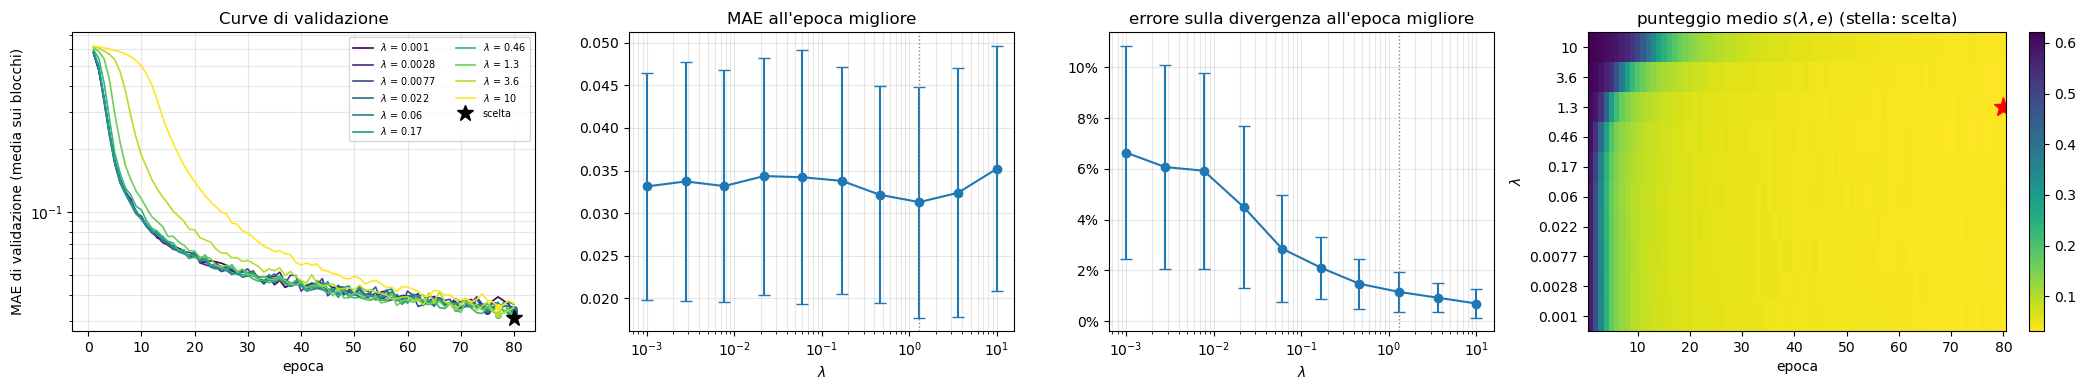

In [97]:
# ---------- riepilogo: curve di validazione medie, scelta di lambda e del numero di epoche
EPOCHE_FINALI = None              # resta None se non ci sono risultati completi: l'addestramento usa allora la validazione fissa
righe = []
for nome in sorted(glob.glob(os.path.join(CARTELLA_KFOLD, 'kfold_lambda_*.csv'))):
    with open(nome) as f:
        righe += [{k: float(v) for k, v in r.items()} for r in csv.DictReader(f)]

if not righe:
    print(f'nessun risultato in {CARTELLA_KFOLD!r}: si usano LAMBDA_DIV = {LAMBDA_DIV:g} e la validazione fissa')
else:
    sd = lambda a: a.std(axis=0, ddof=1) if len(a) > 1 else np.full(a.shape[1:], np.nan)
    curve = {}
    for lam in sorted({r['lambda'] for r in righe}):
        per_blocco = {}
        for r in righe:
            if r['lambda'] == lam:
                per_blocco.setdefault(int(r['blocco']), {})[int(r['epoca'])] = r
        completi = [b for b, rr in per_blocco.items() if len(rr) == EPOCHE_KFOLD]
        if len(completi) < K_FOLD:
            print(f'lambda = {lam:g}: {len(completi)} blocchi completi su {K_FOLD}, escluso dalla scelta')
            continue
        mae = np.array([[per_blocco[b][e]['val_mae'] for e in range(1, EPOCHE_KFOLD + 1)] for b in completi])
        ed = np.array([[per_blocco[b][e]['err_div'] for e in range(1, EPOCHE_KFOLD + 1)] for b in completi])
        curve[lam] = {'mae': mae.mean(0), 'mae_sd': sd(mae), 'div': ed.mean(0), 'div_sd': sd(ed)}

    if curve:
        lams = sorted(curve)
        chiave = 'mae' if CRITERIO == 'mae' else 'div'
        e_best = {l: int(np.argmin(curve[l][chiave])) for l in lams}          # indice dell'epoca migliore per ogni lambda
        print(f'{"lambda":>8} | {"epoca migliore":>14} | {"MAE di validazione":>22} | {"errore divergenza":>20} | {"MAE ultima epoca":>16}')
        for l in lams:
            i = e_best[l]; c = curve[l]
            print(f'{l:>8g} | {i + 1:>14d} | {c["mae"][i]:>11.5f} ± {c["mae_sd"][i]:.5f} | '
                  f'{c["div"][i]:>10.2%} ± {c["div_sd"][i]:.2%} | {c["mae"][-1]:>16.5f}')
        LAMBDA_KFOLD = min(lams, key=lambda l: curve[l][chiave][e_best[l]])
        EPOCHE_FINALI = e_best[LAMBDA_KFOLD] + 1
        LAMBDA_DIV = LAMBDA_KFOLD                     # usato dall'addestramento finale
        print(f'\nscelta (criterio {CRITERIO!r}): LAMBDA_DIV = {LAMBDA_DIV:g}, EPOCHE_FINALI = {EPOCHE_FINALI}')
        print('l\'addestramento finale userà questi valori, su tutte le traiettorie non di test')

        fig, axs = plt.subplots(1, 4, figsize=(21, 4), gridspec_kw={'width_ratios': [1.2, 1, 1, 1.2]})
        colori_l = plt.cm.viridis(np.linspace(0, 1, len(lams)))
        ep = np.arange(1, EPOCHE_KFOLD + 1)
        for l, col in zip(lams, colori_l):
            axs[0].semilogy(ep, curve[l]['mae'], color=col, lw=1.2, label=f'$\\lambda$ = {l:g}')
            axs[0].plot(e_best[l] + 1, curve[l]['mae'][e_best[l]], 'o', color=col, ms=4)
        axs[0].plot(EPOCHE_FINALI, curve[LAMBDA_KFOLD]['mae'][EPOCHE_FINALI - 1], 'k*', ms=12, label='scelta')
        axs[0].set_xlabel('epoca'); axs[0].set_ylabel('MAE di validazione (media sui blocchi)')
        axs[0].set_title('Curve di validazione'); axs[0].legend(fontsize=7, ncol=2); axs[0].grid(True, which='both', alpha=0.3)
        for a, ch, tit in [(axs[1], 'mae', 'MAE all\'epoca migliore'), (axs[2], 'div', 'errore sulla divergenza all\'epoca migliore')]:
            a.errorbar(lams, [curve[l][ch][e_best[l]] for l in lams],
                       yerr=[curve[l][ch + '_sd'][e_best[l]] for l in lams], fmt='o-', capsize=4)
            a.axvline(LAMBDA_KFOLD, color='gray', ls=':', lw=1)
            a.set_xscale('log'); a.set_xlabel(r'$\lambda$'); a.set_title(tit); a.grid(True, which='both', alpha=0.3)
        axs[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
        tabella = np.array([curve[l][chiave] for l in lams])                      # punteggio s(lambda, e)
        im = axs[3].imshow(tabella, aspect='auto', origin='lower', cmap='viridis_r',
                           extent=[0.5, EPOCHE_KFOLD + 0.5, -0.5, len(lams) - 0.5])
        axs[3].plot(EPOCHE_FINALI, lams.index(LAMBDA_KFOLD), 'r*', ms=14)
        axs[3].set_yticks(range(len(lams))); axs[3].set_yticklabels([f'{l:g}' for l in lams])
        axs[3].set_xlabel('epoca'); axs[3].set_ylabel(r'$\lambda$')
        axs[3].set_title('punteggio medio $s(\\lambda, e)$ (stella: scelta)')
        fig.colorbar(im, ax=axs[3], fraction=0.046)
        plt.tight_layout(); plt.show()
    else:
        print('nessun lambda con tutti i blocchi completi: si usano LAMBDA_DIV dei parametri e la validazione fissa')

curve rilette da kfold_congiunta/curve_train_val_lambda_1.3_80ep.npz


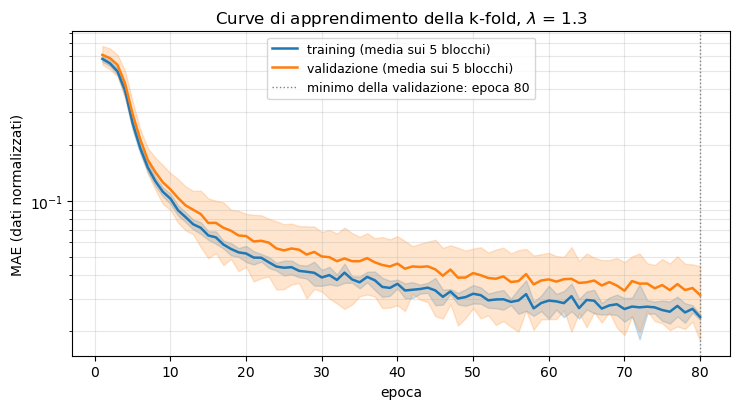

In [98]:
# ---------- curve di training e di validazione per il lambda ottimale scelto, mediate sui 5 blocchi
EPOCHE_CURVE = EPOCHE_KFOLD      # aumentare (per esempio a 60) per vedere se la validazione ha un minimo oltre EPOCHE_KFOLD
lam_c = LAMBDA_DIV
file_curve = os.path.join(CARTELLA_KFOLD, f'curve_train_val_lambda_{lam_c:g}_{EPOCHE_CURVE}ep.npz')

if os.path.exists(file_curve):                                   # già calcolate: si rileggono
    dati_c = np.load(file_curve)
    curve_tr, curve_va = dati_c['train'], dati_c['val']
    print(f'curve rilette da {file_curve}')
else:
    curve_tr, curve_va = [], []
    t_start = time.time()
    for j in range(K_FOLD):                                      # stessi blocchi, seme e lambda della k-fold
        train_seq_f, val_seq_f, punti_va = dati_fold(j)
        torch.manual_seed(SEED_RETE)
        func_c = ODEFunc(HIDDEN_DIM).to(device)
        loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(train_seq_f),
                                             batch_size=BATCH_SIZE, shuffle=True)
        opt = optim.Adam(func_c.parameters(), lr=LR)
        tr, va = [], []
        for epoch in range(1, EPOCHE_CURVE + 1):
            func_c.train()
            for (batch,) in loader:
                opt.zero_grad()
                mae = batch_loss(func_c, batch, t_seq, adjoint=ADJOINT_KFOLD)
                div = divergenza(func_c, batch[:, ::max(1, SEQ_LENGTH // 10), :].reshape(-1, 3))
                pen = (((div - DIV_TARGET) / DIV_TARGET) ** 2).mean()
                l2 = sum(p.pow(2).sum() for p in func_c.parameters())
                (mae + lam_c * pen + L2_LAMBDA * l2).backward()
                opt.step()
            tr.append(evaluate(func_c, train_seq_f, t_seq)[0])   # MAE sui 4 blocchi di addestramento, a fine epoca
            va.append(evaluate(func_c, val_seq_f, t_seq)[0])     # MAE sul blocco lasciato fuori, a fine epoca
        curve_tr.append(tr); curve_va.append(va)
        print(f'blocco {j + 1}/{K_FOLD}: MAE finale train {tr[-1]:.5f} | val {va[-1]:.5f} | {time.time() - t_start:.0f}s')
    curve_tr, curve_va = np.array(curve_tr), np.array(curve_va)
    np.savez(file_curve, train=curve_tr, val=curve_va)

ep_c = np.arange(1, EPOCHE_CURVE + 1)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for curve, nome, col in [(curve_tr, 'training', 'tab:blue'), (curve_va, 'validazione', 'tab:orange')]:
    m, s = curve.mean(axis=0), curve.std(axis=0, ddof=1)           # media e deviazione standard sui blocchi, epoca per epoca
    ax.semilogy(ep_c, m, color=col, lw=1.8, label=f'{nome} (media sui {K_FOLD} blocchi)')
    ax.fill_between(ep_c, m - s, m + s, color=col, alpha=0.2)
i_min = int(np.argmin(curve_va.mean(axis=0)))
ax.axvline(ep_c[i_min], color='gray', ls=':', lw=1, label=f'minimo della validazione: epoca {ep_c[i_min]}')
ax.set_xlabel('epoca'); ax.set_ylabel('MAE (dati normalizzati)')
ax.set_title(f'Curve di apprendimento della k-fold, $\\lambda$ = {lam_c:g}')
ax.legend(fontsize=9); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Addestramento
- **Con i risultati della k-fold** (`EPOCHE_FINALI` impostato dalla cella di riepilogo): la rete si addestra su **tutte le 23 traiettorie non di test** (le 21 di addestramento più le 2 di validazione) per `EPOCHE_FINALI` epoche, con `LAMBDA_DIV` scelto dalla k-fold, e si tiene la rete dell'ultima epoca. Non c'è validazione fissa: numero di epoche e λ sono già stati scelti dalla cross-validation. La normalizzazione resta quella calcolata sulle 21 traiettorie di addestramento: è una trasformazione fissa dei dati e non usa il test.
- **Senza risultati della k-fold**: come prima, addestramento sulle 21 traiettorie per `EPOCHS` epoche, con la MAE delle 2 traiettorie di validazione per scegliere l'epoca; il modello migliore si sceglie solo tra le epoche con la penalità a regime.
- Gradienti con il metodo aggiunto (`ADJOINT = True`) oppure con la backpropagation standard attraverso il risolutore (`ADJOINT = False`): i due metodi danno lo stesso gradiente (controllo precedente), il secondo è più veloce perché non integra all'indietro. Loss MAE più la penalità sulla divergenza con peso `LAMBDA_DIV`, costante con `DIV_START = 1` e `DIV_RAMP = 0`.
- Per ogni epoca si stampano anche la penalità media e la divergenza media sui punti di addestramento: con la penalità attiva, la divergenza deve avvicinarsi a $-13.67$.
- Il termine L2 è aggiunto alla loss ottimizzata ma non è registrato nella MAE stampata.

In [99]:
def lambda_div(epoch):
    # peso della penalità all'epoca `epoch` (da 1): 0 prima di DIV_START, poi rampa lineare fino a LAMBDA_DIV
    if LAMBDA_DIV == 0 or epoch < DIV_START:
        return 0.0
    if DIV_RAMP == 0:
        return LAMBDA_DIV
    return LAMBDA_DIV * min(1.0, (epoch - DIV_START + 1) / DIV_RAMP)

def salva_modello(state, epoch, val_mae, val_mse):
    torch.save({'state_dict': state, 'mean': mean, 'std': std, 'hidden_dim': HIDDEN_DIM,
                'epoch': epoch, 'val_mae': val_mae, 'val_mse': val_mse, 'loss': 'mae',
                'x0s': X0S, 't_transient': T_TRANSIENT, 'lambda_div': LAMBDA_DIV, 'div_start': DIV_START,
                'div_ramp': DIV_RAMP, 'seq_length': SEQ_LENGTH, 'seed_rete': SEED_RETE, 'adjoint': ADJOINT,
                'addestramento': 'k-fold congiunta: 23 traiettorie, ultima epoca' if globals().get('EPOCHE_FINALI') else 'validazione fissa'},
               MODEL_PATH)

def train_neural_ode(func, train_loader, t, epochs, patience, l2_lambda, print_every, con_validazione=True):
    # con_validazione=False: nessuna validazione fissa, si tiene la rete dell'ultima epoca (addestramento finale da k-fold)
    optimizer = optim.Adam(func.parameters(), lr=LR)
    history = {'train_mae': [], 'val_mae': [], 'val_mse': [], 'pen_div': [], 'div_media': [], 'lambda_div': []}
    best_val, best_state, best_epoch, wait = float('inf'), None, 0, 0
    start = time.time()

    for epoch in range(1, epochs + 1):
        func.train()
        ep_start, loss_sum, pen_sum, div_sum, n_seen = time.time(), 0.0, 0.0, 0.0, 0
        lam = lambda_div(epoch)
        # il modello migliore si sceglie solo tra le epoche con la penalità a regime
        selezione = (LAMBDA_DIV == 0) or (lam >= LAMBDA_DIV)
        for (batch,) in train_loader:
            optimizer.zero_grad()
            mae = batch_loss(func, batch, t, adjoint=ADJOINT)              # termine dati (gradiente secondo ADJOINT)
            div = divergenza(func, batch[:, ::max(1, SEQ_LENGTH // 10), :].reshape(-1, 3))   # 10 punti per finestra perchè quelli vicini hanno divergenze quasi simili
            pen_div = (((div - DIV_TARGET) / DIV_TARGET) ** 2).mean()      # errore relativo al quadrato
            l2 = sum(p.pow(2).sum() for p in func.parameters())
            (mae + lam * pen_div + l2_lambda * l2).backward()
            optimizer.step()
            loss_sum += mae.item() * len(batch)
            pen_sum += pen_div.item() * len(batch)
            div_sum += div.mean().item() * len(batch)
            n_seen += len(batch)

        train_mae = loss_sum / n_seen
        history['pen_div'].append(pen_sum / n_seen)
        history['div_media'].append(div_sum / n_seen)
        history['lambda_div'].append(lam)
        history['train_mae'].append(train_mae)
        if con_validazione:
            val_mae, val_mse = evaluate(func, val_seq, t)
            history['val_mae'].append(val_mae)
            history['val_mse'].append(val_mse)
        else:
            val_mae = val_mse = float('nan')
            selezione = False                       # nessuna scelta dell'epoca: si salva l'ultima alla fine

        if selezione and val_mae < best_val:
            best_val, best_epoch, wait = val_mae, epoch, 0
            best_state = copy.deepcopy(func.state_dict())
            salva_modello(best_state, epoch, val_mae, val_mse)
        elif selezione:
            wait += 1

        if epoch % print_every == 0 or epoch == 1:
            val_txt = f'val MAE {val_mae:.5f} | val MSE {val_mse:.6f} | ' if con_validazione else ''
            print(f'Epoch {epoch}/{epochs} | train MAE {train_mae:.5f} | {val_txt}lambda {lam:g} | pen div {history["pen_div"][-1]:.2e} | '
                  f'div media {history["div_media"][-1]:.2f} | {time.time() - ep_start:.1f}s')
        if wait >= patience:
            print(f'Early stopping all\'epoca {epoch}')
            break

    if not con_validazione:  # addestramento finale da k-fold: si tiene l'ultima epoca
        best_state, best_epoch = copy.deepcopy(func.state_dict()), epoch
        salva_modello(best_state, epoch, float('nan'), float('nan'))
    elif best_state is None:   # nessuna epoca con la penalità a regime (EPOCHS troppo basso)
        print('ATTENZIONE: la penalità non ha mai raggiunto LAMBDA_DIV; si tiene il modello dell\'ultima epoca')
        best_state, best_epoch = copy.deepcopy(func.state_dict()), epoch
        salva_modello(best_state, epoch, float('nan'), float('nan'))
    func.load_state_dict(best_state)
    if con_validazione:
        print(f'Fine. Miglior epoca: {best_epoch} (val MAE {best_val:.5f}). Tempo totale: {time.time() - start:.0f}s')
    else:
        print(f'Fine. Tenuta l\'ultima epoca ({best_epoch}). Tempo totale: {time.time() - start:.0f}s')
    return history

torch.manual_seed(SEED_RETE)                 # pesi iniziali e ordine dei batch dipendono solo da SEED_RETE
func = ODEFunc(HIDDEN_DIM).to(device)
if globals().get('EPOCHE_FINALI'):
    # scelte della k-fold: tutte le 23 traiettorie non di test, EPOCHE_FINALI epoche, ultima epoca
    # normalizzazione della rete finale: statistiche di tutte le 23 traiettorie non di test
    finali = trajs[:N_TRAJ - N_TEST_TRAJ]
    mean = np.concatenate(finali).mean(axis=0)
    std = np.concatenate(finali).std(axis=0)
    # finestre e test ricostruiti con la nuova normalizzazione (normalize usa mean e std appena calcolate)
    train_seq = torch.cat([create_sequences(to_tensor(normalize(a)), SEQ_LENGTH) for a in train_list])
    val_seq   = torch.cat([create_sequences(to_tensor(normalize(a)), SEQ_LENGTH) for a in val_list])
    test_n    = [to_tensor(normalize(a)) for a in test_list]
    test_seq  = torch.cat([create_sequences(a, SEQ_LENGTH) for a in test_n])
    print(f'normalizzazione finale su {len(finali)} traiettorie: media {mean.round(2)}, std {std.round(2)}')
    loader_finale = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(torch.cat([train_seq, val_seq])),
                                                batch_size=BATCH_SIZE, shuffle=True)
    print(f'addestramento finale: {len(train_seq) + len(val_seq)} finestre (23 traiettorie), '
          f'LAMBDA_DIV = {LAMBDA_DIV:g}, {EPOCHE_FINALI} epoche')
    history = train_neural_ode(func, loader_finale, t_seq, EPOCHE_FINALI, PATIENCE, L2_LAMBDA, PRINT_EVERY,
                               con_validazione=False)
else:
    print(f'addestramento con validazione fissa: LAMBDA_DIV = {LAMBDA_DIV:g}, {EPOCHS} epoche')
    history = train_neural_ode(func, train_loader, t_seq, EPOCHS, PATIENCE, L2_LAMBDA, PRINT_EVERY)

normalizzazione finale su 23 traiettorie: media [-0.09 -0.09 25.12], std [ 8.32 10.01  8.88]
addestramento finale: 6946 finestre (23 traiettorie), LAMBDA_DIV = 1.3, 80 epoche
Epoch 1/80 | train MAE 0.60475 | lambda 1.3 | pen div 1.79e-01 | div media -10.44 | 3.7s
Epoch 2/80 | train MAE 0.55658 | lambda 1.3 | pen div 1.97e-02 | div media -13.23 | 3.8s
Epoch 3/80 | train MAE 0.49395 | lambda 1.3 | pen div 1.03e-02 | div media -13.45 | 3.8s
Epoch 4/80 | train MAE 0.34657 | lambda 1.3 | pen div 1.06e-02 | div media -13.46 | 4.3s
Epoch 5/80 | train MAE 0.21674 | lambda 1.3 | pen div 7.58e-03 | div media -13.51 | 4.7s
Epoch 6/80 | train MAE 0.15896 | lambda 1.3 | pen div 5.79e-03 | div media -13.52 | 5.0s
Epoch 7/80 | train MAE 0.12856 | lambda 1.3 | pen div 4.27e-03 | div media -13.55 | 5.1s
Epoch 8/80 | train MAE 0.10903 | lambda 1.3 | pen div 3.40e-03 | div media -13.57 | 5.1s
Epoch 9/80 | train MAE 0.09607 | lambda 1.3 | pen div 2.82e-03 | div media -13.58 | 5.2s
Epoch 10/80 | train MAE 

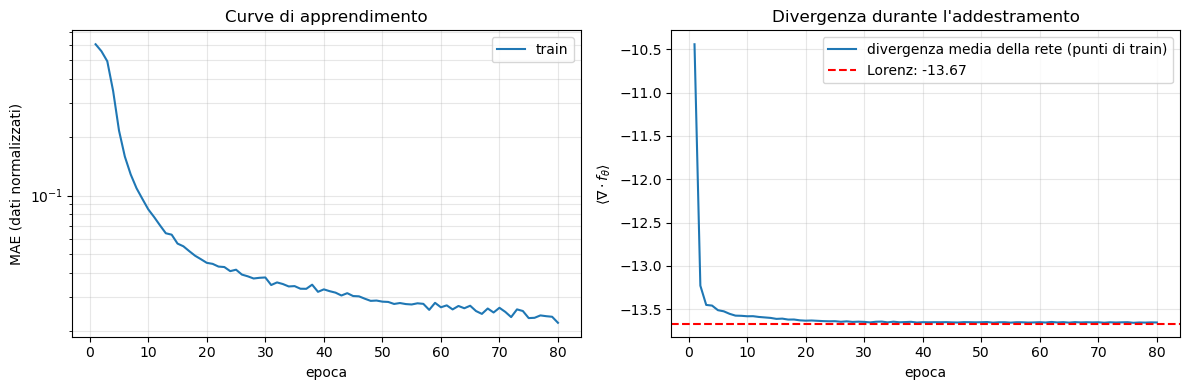

In [100]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
ep = range(1, len(history['train_mae']) + 1)
axs[0].semilogy(ep, history['train_mae'], label='train')
if history['val_mae']:                       # assente nell'addestramento finale da k-fold
    axs[0].semilogy(ep, history['val_mae'], label='validazione')
axs[0].set_xlabel('epoca'); axs[0].set_ylabel('MAE (dati normalizzati)'); axs[0].set_title('Curve di apprendimento')
axs[0].legend(); axs[0].grid(True, which='both', alpha=0.3)
axs[1].plot(ep, history['div_media'], label='divergenza media della rete (punti di train)')
axs[1].axhline(DIV_TARGET, color='red', ls='--', label=f'Lorenz: {DIV_TARGET:.2f}')
axs[1].set_xlabel('epoca'); axs[1].set_ylabel(r'$\langle\nabla\cdot f_\theta\rangle$'); axs[1].set_title('Divergenza durante l\'addestramento')
if LAMBDA_DIV > 0 and DIV_START > 1:
    for ax in axs:
        ax.axvline(DIV_START, color='gray', ls=':', lw=1)
    axs[1].text(DIV_START, axs[1].get_ylim()[1], ' penalità accesa', va='top', fontsize=8, color='gray')
axs[1].legend(); axs[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## Test
1. **Errore a breve orizzonte** sulle finestre di test : MAE, e MSE per confronto.
2. **Traiettoria lunga** a partire dal primo punto del primo pezzo di test: dopo qualche tempo di Lyapunov ($1/\mu_1 \approx 1.1$) la predizione si separa dalla vera, quindi qui si guarda soprattutto la forma dell'attrattore.

In [101]:
test_mae, test_mse = evaluate(func, test_seq, t_seq)
print(f'test (finestre da {SEQ_LENGTH} punti, dati normalizzati): MAE {test_mae:.5f} | MSE {test_mse:.6f}')

func.eval()
t_test = t_np[:len(test_list[0])]          # tempi del primo pezzo di test, da 0
with torch.no_grad():
    pred_test = integrate(func, test_n[0][:1], to_tensor(t_test), adjoint=False).squeeze(1).cpu().numpy()
pred_test = denormalize(pred_test)
true_test = test_list[0]

test (finestre da 100 punti, dati normalizzati): MAE 0.00891 | MSE 0.000467


In [116]:
# ---------- test esteso: nuove traiettorie mai viste (seme e numero fissati a priori)
N_TEST_EXTRA, SEED_TEST_EXTRA = 10, 1
X0_EXTRA = np.random.default_rng(SEED_TEST_EXTRA).uniform(BOX_LO, BOX_HI, size=(N_TEST_EXTRA, 3))
mae_extra, mse_extra = [], []
for x0 in X0_EXTRA:
    _, s = generate_lorenz_data(x0, DT, T_TRANSIENT, T_DATA)
    seq = create_sequences(to_tensor((s - mean) / std), SEQ_LENGTH)   # normalizzazione dell'addestramento finale
    m_, q_ = evaluate(func, seq, t_seq)
    mae_extra.append(m_); mse_extra.append(q_)
mae_extra, mse_extra = np.array(mae_extra), np.array(mse_extra)
print(f'test esteso su {N_TEST_EXTRA} nuove traiettorie: MAE {mae_extra.mean():.5f} | MSE {mse_extra.mean():.6f} '
      f'| per traiettoria da {mae_extra.min():.4f} a {mae_extra.max():.4f}')

test esteso su 10 nuove traiettorie: MAE 0.01902 | MSE 0.005902 | per traiettoria da 0.0040 a 0.0542


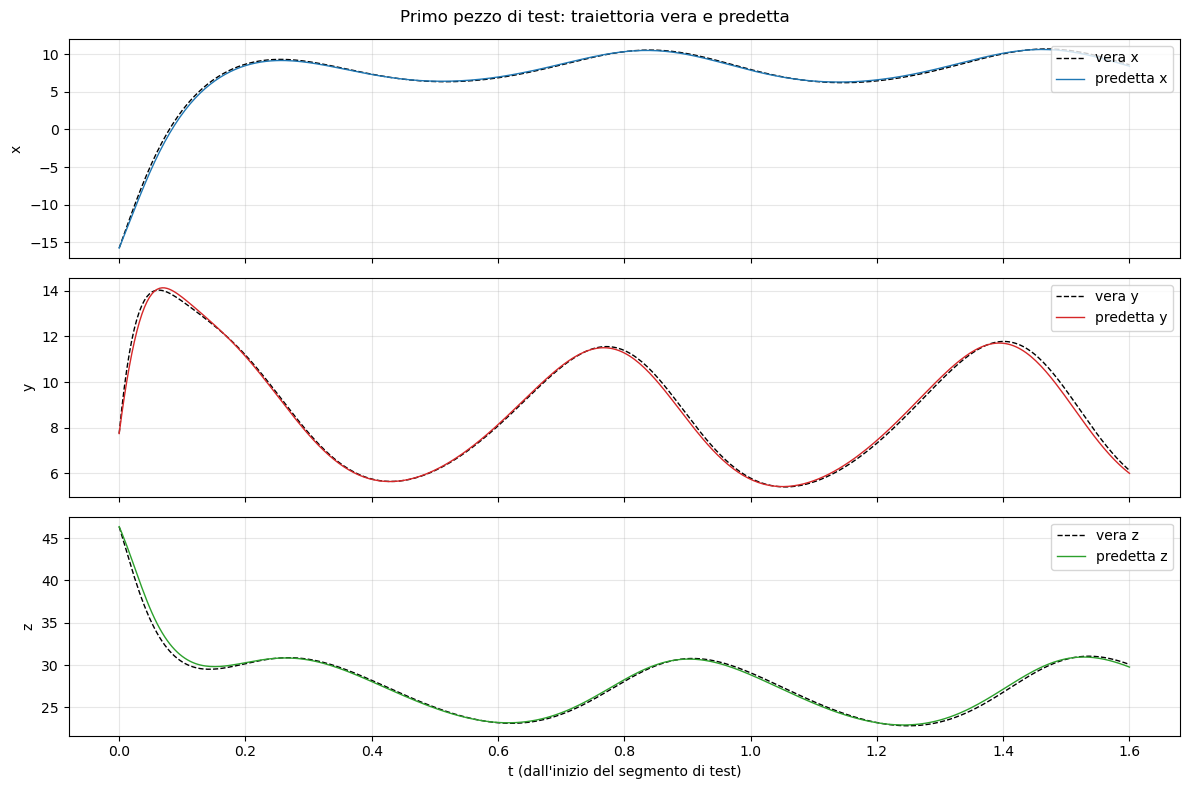

In [102]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for k, (name, c) in enumerate(zip('xyz', ['tab:blue', 'tab:red', 'tab:green'])):
    axes[k].plot(t_test, true_test[:, k], '--', color='black', lw=1, label=f'vera {name}')
    axes[k].plot(t_test, pred_test[:, k], color=c, lw=1, label=f'predetta {name}')
    axes[k].set_ylabel(name); axes[k].legend(loc='upper right'); axes[k].grid(True, alpha=0.3)
axes[-1].set_xlabel('t (dall\'inizio del segmento di test)')
plt.suptitle('Primo pezzo di test: traiettoria vera e predetta'); plt.tight_layout(); plt.show()

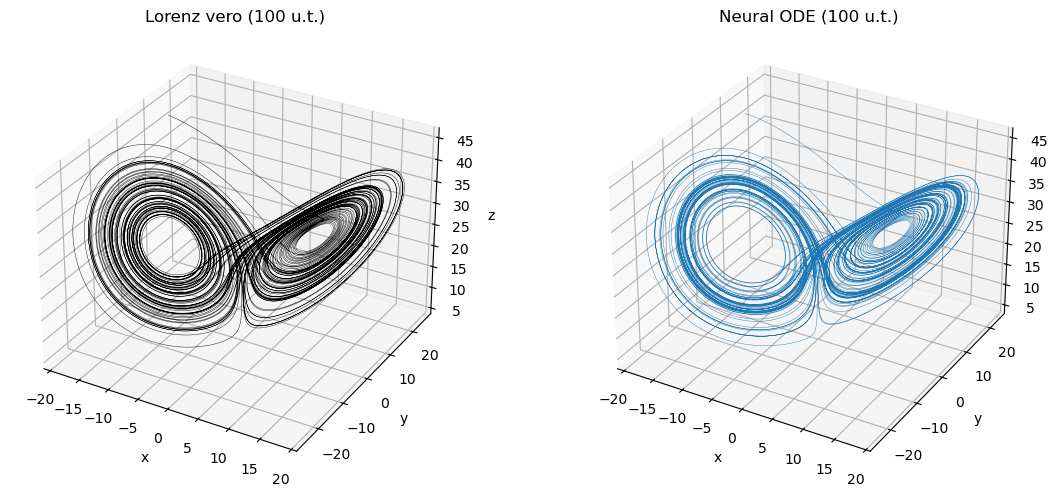

In [103]:
# Attrattore: traiettoria lunga del modello, confrontata con una lunga traiettoria vera
T_LONG = 100.0
t_long = np.arange(0.0, T_LONG, DT)
with torch.no_grad():
    pred_long = integrate(func, test_n[0][:1], to_tensor(t_long), adjoint=False).squeeze(1).cpu().numpy()
pred_long = denormalize(pred_long)
_, true_long = generate_lorenz_data(true_test[0], DT, 0.0, T_LONG)

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot(*true_long.T, color='black', lw=0.3); ax1.set_title(f'Lorenz vero ({T_LONG:.0f} u.t.)')
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot(*pred_long.T, color='tab:blue', lw=0.3); ax2.set_title(f'Neural ODE ({T_LONG:.0f} u.t.)')
for ax in (ax1, ax2):
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
plt.tight_layout(); plt.show()

---
## Esponenti di Lyapunov: Lorenz vero e rete addestrata

Una loss bassa dice che la rete riproduce bene le traiettorie su un orizzonte breve (0.4 unità di tempo), ma non garantisce che la dinamica sull'attrattore sia quella giusta. Per verificarlo si confrontano gli **spettri di Lyapunov** e le grandezze derivate (dimensione di Kaplan–Yorke $D_{KY}$, tempo di Lyapunov $t_L = 1/\mu_1$) del sistema di Lorenz e del campo appreso $f_\theta$.

**Metodo.** Algoritmo di Benettin con riortonormalizzazione QR (Magri et al. §1.4.1).

**Coordinate normalizzate.** La rete lavora nelle coordinate $\mathbf z = S^{-1}(\mathbf x - \mathbf m)$, con $S = \mathrm{diag}(s_x, s_y, s_z)$. Il cambio di coordinate è lineare, costante e non tocca il tempo, quindi:
- gli esponenti di Lyapunov non cambiano (il propagatore diventa $S^{-1}U S$, che ha la stessa crescita esponenziale);
- non cambia nemmeno la divergenza, perché $\operatorname{tr}(S^{-1}JS) = \operatorname{tr}J$: la somma degli esponenti della rete si confronta direttamente con $-(\sigma+1+\beta)$.

Gli esponenti della rete si calcolano quindi direttamente in $\mathbf z$.

**Jacobiana della rete.** Si usa la formula esatta ottenuta con la regola della catena sui layer Linear e tanh: è molto più veloce di `torch.func.jacrev` chiamata a ogni passo (decine di microsecondi invece di millisecondi), e la prima cella controlla che coincida con l'autodiff.

**Per eseguire questa parte senza riaddestrare:** dopo un riavvio del kernel basta eseguire le celle di import, dei parametri e del modello (`ODEFunc`), poi questa sezione: i pesi vengono letti da `MODEL_PATH`.

In [104]:
# ---------- modello salvato ----------
ck = torch.load(MODEL_PATH, weights_only=False, map_location='cpu')
rete = ODEFunc(ck['hidden_dim'])
rete.load_state_dict(ck['state_dict'])
rete.eval()
mean_ck, std_ck = ck['mean'], ck['std']      # normalizzazione usata in addestramento
print(f"modello dell'epoca {ck['epoch']}, val MSE {ck['val_mse']:.5f}")

# pesi della rete in NumPy (float64), per campo e jacobiana veloci
strati = []
for layer in rete.net:
    if isinstance(layer, nn.Linear):
        strati.append(('lin', layer.weight.detach().double().numpy(), layer.bias.detach().double().numpy()))
    elif isinstance(layer, nn.Tanh):
        strati.append(('tanh', None, None))
    else:
        raise ValueError(f'strato non gestito: {layer}')

def f_rete(z):
    a = z
    for tipo, W, b in strati:
        a = W @ a + b if tipo == 'lin' else np.tanh(a)
    return a

def J_rete(z):
    # regola della catena: J = W_L D_{L-1} W_{L-1} ... D_1 W_1, con D = diag(1 - tanh^2)
    a, Jm = z, np.eye(len(z))
    for tipo, W, b in strati:
        if tipo == 'lin':
            a, Jm = W @ a + b, W @ Jm
        else:
            a = np.tanh(a)
            Jm = (1.0 - a**2)[:, None] * Jm
    return Jm

# ---------- Lorenz vero ----------
def f_lorenz(x):
    return np.array([SIGMA * (x[1] - x[0]),
                     x[0] * (RHO - x[2]) - x[1],
                     x[0] * x[1] - BETA * x[2]])

def J_lorenz(x):
    return np.array([[-SIGMA,    SIGMA,  0.0],
                     [RHO - x[2], -1.0, -x[0]],
                     [x[1],       x[0], -BETA]])

# ---------- controlli ----------
rete64 = copy.deepcopy(rete.net).double()
rng = np.random.default_rng(1)
err_f = err_J = 0.0
for _ in range(5):
    z = rng.normal(size=3)
    zt = torch.tensor(z)
    with torch.no_grad():
        err_f = max(err_f, np.abs(f_rete(z) - rete64(zt).numpy()).max())
    err_J = max(err_J, np.abs(J_rete(z) - torch.func.jacrev(rete64)(zt).detach().numpy()).max())
print(f'campo della rete: differenza massima da PyTorch           = {err_f:.1e}')
print(f'jacobiana della rete: differenza massima da torch.func.jacrev = {err_J:.1e}')

modello dell'epoca 80, val MSE nan
campo della rete: differenza massima da PyTorch           = 7.1e-15
jacobiana della rete: differenza massima da torch.func.jacrev = 7.1e-15


In [105]:
def rk4_step(f, x, dt):
    k1 = f(x); k2 = f(x + 0.5 * dt * k1); k3 = f(x + 0.5 * dt * k2); k4 = f(x + dt * k3)
    return x + dt / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)

def rk4_var_step(f, J, x, U, dt):
    # sistema aumentato: x' = f(x),  U' = J(x) U  (stadi di U valutati negli stessi punti degli stadi di x)
    k1 = f(x);              m1 = J(x) @ U
    x2 = x + 0.5 * dt * k1; k2 = f(x2); m2 = J(x2) @ (U + 0.5 * dt * m1)
    x3 = x + 0.5 * dt * k2; k3 = f(x3); m3 = J(x3) @ (U + 0.5 * dt * m2)
    x4 = x + dt * k3;       k4 = f(x4); m4 = J(x4) @ (U + dt * m3)
    return (x + dt / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4),
            U + dt / 6.0 * (m1 + 2 * m2 + 2 * m3 + m4))

def spettro_lyapunov(f, J, x0, dt, t_trans, T, seed=0):
    # spettro con Benettin/QR; restituisce esponenti finali, medie cumulative e media di tr J lungo l'orbita
    x = np.array(x0, dtype=float)
    for _ in range(int(round(t_trans / dt))):           # transitorio: arrivo sull'attrattore
        x = rk4_step(f, x, dt)
    n = len(x)
    Q, _ = np.linalg.qr(np.random.default_rng(seed).standard_normal((n, n)))
    N = int(round(T / dt))
    log_R = np.empty((N, n))
    traccia = 0.0
    for k in range(N):
        x, Q = rk4_var_step(f, J, x, Q, dt)
        Q, Rm = np.linalg.qr(Q)                          # riortonormalizzazione
        log_R[k] = np.log(np.abs(np.diag(Rm)))
        traccia += np.trace(J(x))
    t = np.arange(1, N + 1) * dt
    lam_cum = np.cumsum(log_R, axis=0) / t[:, None]
    return dict(lam=lam_cum[-1], lam_cum=lam_cum, t=t, traccia=traccia / N)

def kaplan_yorke(lam):
    # D_KY = k + (mu_1 + ... + mu_k) / |mu_{k+1}|, con k il più grande intero per cui la somma parziale è >= 0
    s = np.cumsum(lam)
    k = int(np.sum(s >= 0))          # le somme parziali decrescono dopo il primo esponente negativo
    if k == 0:
        return 0.0
    if k == len(lam):
        return float(k)
    return k + s[k - 1] / abs(lam[k])

### Calcolo degli spettri
Si usano `M_CI` condizioni iniziali casuali, le stesse per i due sistemi (per la rete, normalizzate). Da ciascuna si scarta un transitorio di `T_TRANS_LYAP` unità di tempo, così che l'orbita sia sull'attrattore *del proprio sistema*: quello di Lorenz per Lorenz, quello appreso per la rete. Per l'ipotesi di ergodicità lo spettro non dovrebbe dipendere dalla condizione iniziale: la dispersione tra le `M_CI` stime misura l'incertezza numerica del calcolo.

Con questi valori il calcolo richiede qualche minuto.

In [106]:
DT_LYAP = 0.01          # passo RK4 (come in Magri et al.)
T_TRANS_LYAP = 50.0     # transitorio scartato
T_LYAP = 1000.0         # durata dell'integrazione (circa 900 tempi di Lyapunov)
M_CI = 5                # numero di condizioni iniziali

SEED_LYAP = 2
rng = np.random.default_rng(SEED_LYAP)
ci = rng.uniform([-15, -15, 10], [15, 15, 40], size=(M_CI, 3))

ris_lorenz, ris_rete = [], []
t_start = time.time()
for k, x0 in enumerate(ci):
    ris_lorenz.append(spettro_lyapunov(f_lorenz, J_lorenz, x0, DT_LYAP, T_TRANS_LYAP, T_LYAP, seed=k))
    ris_rete.append(spettro_lyapunov(f_rete, J_rete, (x0 - mean_ck) / std_ck, DT_LYAP, T_TRANS_LYAP, T_LYAP, seed=k))
    print(f'CI {k}: Lorenz {np.round(ris_lorenz[-1]["lam"], 4)}   rete {np.round(ris_rete[-1]["lam"], 4)}   '
          f'({time.time() - t_start:.0f}s)')

lam_L = np.array([r['lam'] for r in ris_lorenz])
lam_N = np.array([r['lam'] for r in ris_rete])

CI 0: Lorenz [  0.8977   0.     -14.5643]   rete [ 8.89200e-01  1.20000e-03 -1.45585e+01]   (223s)
CI 1: Lorenz [ 9.07800e-01 -3.00000e-03 -1.45713e+01]   rete [ 8.93600e-01 -3.40000e-03 -1.45577e+01]   (286s)
CI 2: Lorenz [ 9.05200e-01 -2.00000e-03 -1.45697e+01]   rete [ 8.91900e-01 -7.00000e-04 -1.45596e+01]   (377s)
CI 3: Lorenz [ 9.0770e-01 -3.0000e-04 -1.4574e+01]   rete [ 8.88200e-01  4.00000e-04 -1.45571e+01]   (419s)
CI 4: Lorenz [ 9.02900e-01  8.00000e-04 -1.45702e+01]   rete [ 8.88800e-01 -2.00000e-04 -1.45557e+01]   (460s)


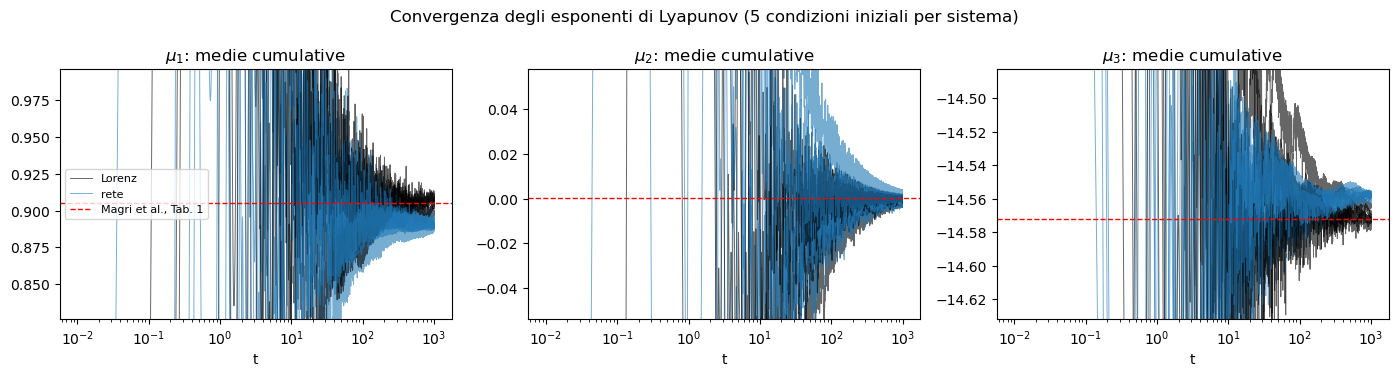

In [107]:
RIF_MAGRI = np.array([0.9050, 9e-5, -14.572])      # Tab. 1 di Magri et al. (riportata nella tesi)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for i in range(3):
    for k in range(M_CI):
        axs[i].plot(ris_lorenz[k]['t'], ris_lorenz[k]['lam_cum'][:, i], color='black', lw=0.7, alpha=0.6,
                    label='Lorenz' if k == 0 else None)
        axs[i].plot(ris_rete[k]['t'], ris_rete[k]['lam_cum'][:, i], color='tab:blue', lw=0.7, alpha=0.6,
                    label='rete' if k == 0 else None)
    axs[i].axhline(RIF_MAGRI[i], color='red', ls='--', lw=1, label='Magri et al., Tab. 1')
    coda = np.concatenate([r['lam_cum'][len(r['t']) // 10:, i] for r in ris_lorenz + ris_rete])   # senza il primo 10%
    pad = max(coda.max() - coda.min(), 0.05)
    axs[i].set_ylim(coda.min() - 0.3 * pad, coda.max() + 0.3 * pad)
    axs[i].set_xscale('log'); axs[i].set_xlabel('t'); axs[i].set_title(f'$\\mu_{i+1}$: medie cumulative')
axs[0].legend(fontsize=8)
plt.suptitle(f'Convergenza degli esponenti di Lyapunov ({M_CI} condizioni iniziali per sistema)')
plt.tight_layout(); plt.show()

In [108]:
def riga(nome, lam_mean, lam_std=None, somma=None, div=None):
    fmt = lambda v, s: f'{v:9.4f}' + (f' ± {s:.4f}' if s is not None else '         ')
    dky = kaplan_yorke(lam_mean)
    s = lam_mean.sum() if somma is None else somma
    print(f'{nome:22s}' + ''.join(fmt(lam_mean[i], None if lam_std is None else lam_std[i]) for i in range(3))
          + f'   {s:9.4f}' + (f'   {div:9.4f}' if div is not None else '            ')
          + f'   {dky:7.4f}   ' + (f'{1 / lam_mean[0]:6.3f}' if lam_mean[0] > 0 else '     -'))   # t_L solo se mu_1 > 0

div_L = np.mean([r['traccia'] for r in ris_lorenz])
div_N = np.mean([r['traccia'] for r in ris_rete])
print(f'{"":22s}' + ''.join(f'{"mu_" + str(i + 1):>18s}' for i in range(3))
      + f'{"somma":>12s}{"<div f>":>12s}{"D_KY":>10s}{"t_L":>9s}')
riga('Lorenz (questo codice)', lam_L.mean(0), lam_L.std(0), div=div_L)
riga('Magri et al., Tab. 1', RIF_MAGRI)
riga('Neural ODE', lam_N.mean(0), lam_N.std(0), div=div_N)
print(f'\n-(sigma + 1 + beta) = {-(SIGMA + 1 + BETA):.4f}')

err_rel = np.abs(lam_N.mean(0) - lam_L.mean(0)) / np.abs(lam_L.mean(0))
print(f'errore relativo rete vs Lorenz: mu_1 {err_rel[0]:.1%},  mu_3 {err_rel[2]:.1%},  '
      f'D_KY {abs(kaplan_yorke(lam_N.mean(0)) - kaplan_yorke(lam_L.mean(0))) / kaplan_yorke(lam_L.mean(0)):.1%}')

                                    mu_1              mu_2              mu_3       somma     <div f>      D_KY      t_L
Lorenz (questo codice)   0.9042 ± 0.0037  -0.0009 ± 0.0014 -14.5699 ± 0.0032    -13.6666    -13.6667    2.0620    1.106
Magri et al., Tab. 1     0.9050            0.0001          -14.5720             -13.6669                2.0621    1.105
Neural ODE               0.8904 ± 0.0021  -0.0005 ± 0.0016 -14.5577 ± 0.0013    -13.6679    -13.6680    2.0611    1.123

-(sigma + 1 + beta) = -13.6667
errore relativo rete vs Lorenz: mu_1 1.5%,  mu_3 0.1%,  D_KY 0.0%


In [109]:
# ---------- distanza tra lo spettro della rete e quello di Lorenz
mu_L, mu_N = lam_L.mean(0), lam_N.mean(0)                 # spettri medi sulle condizioni iniziali
diff = mu_N - mu_L
d_abs = np.linalg.norm(diff)                              # norma euclidea della differenza
d_rel = d_abs / np.linalg.norm(mu_L)                      # relativa alla norma dello spettro di Lorenz
rumore = np.mean([np.linalg.norm(l - mu_L) for l in lam_L])   # dispersione di Lorenz tra condizioni iniziali

print(f'||mu_rete - mu_Lorenz||                  = {d_abs:.4f}')
print(f'||mu_rete - mu_Lorenz|| / ||mu_Lorenz||  = {d_rel:.2%}')
print(f'riferimento: <||mu_Lorenz(x0) - mu_Lorenz||> = {rumore:.4f}   (rumore numerico del calcolo)')
print('quota di ciascun esponente nel quadrato della norma (mu_1, mu_2, mu_3):',
      np.round(diff**2 / d_abs**2, 3))

||mu_rete - mu_Lorenz||                  = 0.0185
||mu_rete - mu_Lorenz|| / ||mu_Lorenz||  = 0.13%
riferimento: <||mu_Lorenz(x0) - mu_Lorenz||> = 0.0044   (rumore numerico del calcolo)
quota di ciascun esponente nel quadrato della norma (mu_1, mu_2, mu_3): [0.564 0.    0.436]


**Come leggere il confronto.**
- La riga di Lorenz calcolata con questo codice va confrontata prima con la Tab. 1 di Magri et al.: è il controllo che il codice funziona. La sua deviazione standard tra condizioni iniziali è il livello di rumore numerico: differenze tra rete e Lorenz più piccole di questa non sono significative.
- Per la rete, $\mu_2$ deve risultare vicino a zero (flusso autonomo su un attrattore che non è un punto fisso) e la somma degli esponenti deve coincidere con la media della divergenza $\langle\nabla\cdot f_\theta\rangle$ lungo l'orbita (formula di Liouville): questi due controlli valgono per qualsiasi campo e verificano il calcolo, non il modello.
- Il confronto vero riguarda $\mu_1$ (sensibilità alle condizioni iniziali, quindi $t_L$), $\mu_3$ (contrazione trasversale all'attrattore) e $D_{KY}$ (geometria dell'attrattore). Un buon accordo indica che la rete riproduce la dinamica sull'attrattore e non solo le traiettorie a breve termine; un disaccordo, a parità di loss bassa, è esattamente il caso in cui la loss non basta come metrica.
- $\langle\nabla\cdot f_\theta\rangle$ è un indicatore a sé: per Lorenz la divergenza è costante, $-(\sigma+1+\beta)$, mentre per la rete varia da punto a punto e conta solo la sua media sull'attrattore appreso.

---
## Controlli a posteriori della dinamica appresa

Lo spettro di Lyapunov confronta i tassi di crescita e di contrazione delle perturbazioni. I controlli che seguono confrontano altre proprietà dell'attrattore appreso con quelle di Lorenz: la sua struttura, attraverso la mappa di Lorenz, e la sua simmetria. Sono eseguiti in coordinate fisiche, con il campo della rete riportato dalle coordinate normalizzate, $F_\theta(x) = S\,f_\theta\big(S^{-1}(x - m)\big)$, dove $m$ e $S = \mathrm{diag}(s)$ sono media e deviazione standard dei dati di addestramento.

### Mappa di Lorenz

Lungo una traiettoria sull'attrattore, la coordinata $z(t)$ oscilla e raggiunge una successione di massimi locali $z_1, z_2, z_3, \dots$. Lorenz (1963) osservò che, riportando ogni massimo in funzione del precedente, i punti $(z_n, z_{n+1})$ non si distribuiscono a caso ma cadono, con ottima approssimazione, su una curva
$$
z_{n+1} = g(z_n),
$$
a forma di tenda. La dinamica tridimensionale si riduce così, in modo approssimato, a una mappa unidimensionale. Poiché $|g'(z)| > 1$ quasi ovunque, la mappa espande le distanze tra massimi successivi: è l'argomento di Lorenz per l'assenza di orbite periodiche stabili sull'attrattore (cfr. Strogatz, §9.4).

La curva $g$ è una proprietà dell'attrattore, non di una singola traiettoria. Per questo la si può confrontare tra Lorenz e rete anche su tempi lunghi, dove le traiettorie non sono più confrontabili punto per punto.

**Procedura.** Per Lorenz e per la rete si integrano traiettorie lunghe dalle stesse condizioni iniziali usate per lo spettro, scartando il transitorio, e si estraggono i massimi locali di $z$. Si confronta:
- **visivamente**, sovrapponendo le due mappe $(z_n, z_{n+1})$;
- **quantitativamente**, con l'intervallo occupato dai massimi e con lo scarto medio dei punti della rete dalla curva di Lorenz, $\langle |z_{n+1} - g_L(z_n)| \rangle$, dove $g_L$ è la curva di Lorenz stimata dai suoi punti (mediana per intervalli di $z_n$). Lo stesso scarto calcolato per i punti di Lorenz dà lo spessore intrinseco della mappa, cioè il riferimento sotto il quale le differenze non sono significative.

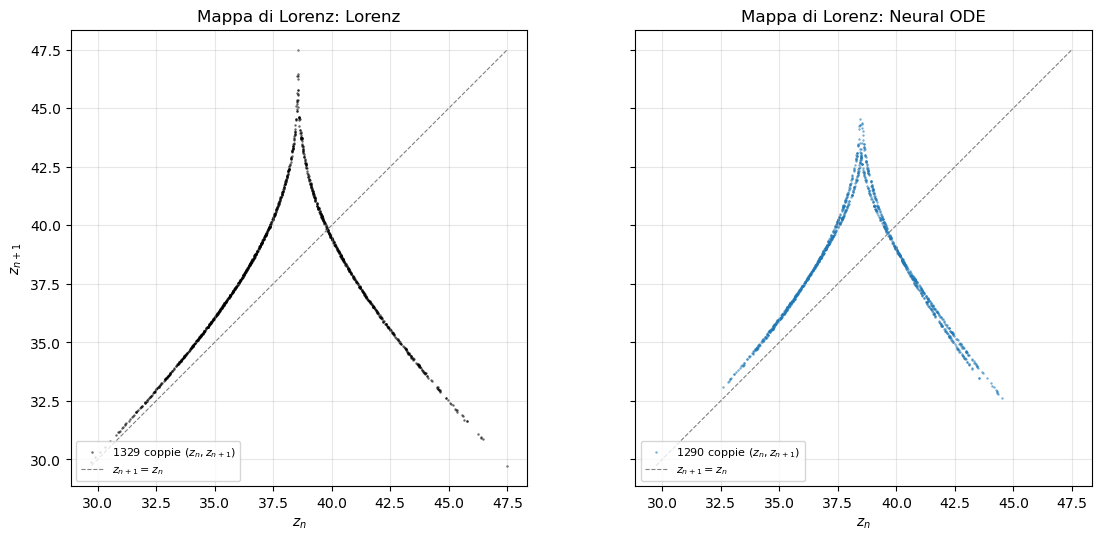

massimi di z      Lorenz: da 29.73 a 47.47   rete: da 32.61 a 44.53
numero di massimi per unità di tempo   Lorenz: 1.334   rete: 1.295
scarto medio dalla curva di Lorenz      Lorenz (spessore della mappa): 0.080   rete: 0.392   (100.0% dei punti della rete nell'intervallo di Lorenz)


In [115]:
def F_rete(x):
    # campo della rete in coordinate fisiche: dx/dt = S f(S^-1 (x - m)), con S = diag(std) e m la media
    return std_ck * f_rete((x - mean_ck) / std_ck)

T_MAPPA = 200.0      # durata utile di ogni traiettoria (dopo un transitorio di 50 u.t.)

def massimi_z(f, x0):
    # massimi locali successivi di z(t) lungo una traiettoria sull'attrattore
    x = np.array(x0, dtype=float)
    for _ in range(int(round(50 / DT_LYAP))):            # transitorio scartato
        x = rk4_step(f, x, DT_LYAP)
    z = np.empty(int(round(T_MAPPA / DT_LYAP)))
    for k in range(len(z)):
        x = rk4_step(f, x, DT_LYAP)
        z[k] = x[2]
    i = np.where((z[1:-1] > z[:-2]) & (z[1:-1] > z[2:]))[0] + 1     # punti più alti dei due vicini
    return z[i]

def mappa(f):
    # coppie (z_n, z_{n+1}) da tutte le condizioni iniziali; le coppie non attraversano traiettorie diverse
    zn, zn1 = [], []
    for x0 in ci:
        m = massimi_z(f, x0)
        zn.append(m[:-1]); zn1.append(m[1:])
    return np.concatenate(zn), np.concatenate(zn1)

zn_L, zn1_L = mappa(f_lorenz)
zn_N, zn1_N = mappa(F_rete)

# curva di Lorenz g_L: mediana di z_{n+1} per intervalli di z_n, poi interpolazione lineare
bordi = np.linspace(zn_L.min(), zn_L.max(), 61)
centri, mediane = [], []
for lo, hi in zip(bordi[:-1], bordi[1:]):
    sel = (zn_L >= lo) & (zn_L < hi)
    if sel.sum() >= 5:
        centri.append(0.5 * (lo + hi)); mediane.append(np.median(zn1_L[sel]))
g_L = lambda z: np.interp(z, centri, mediane)

# ---------- figure affiancate
fig, axs = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, (zn, zn1, tit, col) in zip(axs, [(zn_L, zn1_L, 'Lorenz', 'black'), (zn_N, zn1_N, 'Neural ODE', 'tab:blue')]):
    ax.scatter(zn, zn1, s=3, color=col, alpha=0.6, linewidths=0, label=f'{len(zn)} coppie $(z_n, z_{{n+1}})$')
    ax.set_title(f'Mappa di Lorenz: {tit}')
    ax.set_xlabel('$z_n$')
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
zz = np.linspace(min(zn_L.min(), zn_N.min()), max(zn_L.max(), zn_N.max()), 200)
for ax in axs:
    ax.plot(zz, zz, color='gray', ls='--', lw=0.8, label='$z_{n+1} = z_n$')
axs[0].set_ylabel('$z_{n+1}$')
for ax in axs:
    ax.legend(loc='lower left', fontsize=8)
plt.tight_layout(); plt.show()

# ---------- confronto numerico
dentro = (zn_N >= zn_L.min()) & (zn_N <= zn_L.max())     # punti della rete nell'intervallo coperto dalla curva di Lorenz
spessore = np.abs(zn1_L - g_L(zn_L)).mean()
scarto = np.abs(zn1_N[dentro] - g_L(zn_N[dentro])).mean()
print(f'massimi di z      Lorenz: da {zn_L.min():.2f} a {zn_L.max():.2f}   rete: da {zn_N.min():.2f} a {zn_N.max():.2f}')
print(f'numero di massimi per unità di tempo   Lorenz: {(len(zn_L) + len(ci)) / (len(ci) * T_MAPPA):.3f}   '
      f'rete: {(len(zn_N) + len(ci)) / (len(ci) * T_MAPPA):.3f}')
print(f'scarto medio dalla curva di Lorenz      Lorenz (spessore della mappa): {spessore:.3f}   '
      f'rete: {scarto:.3f}   ({dentro.mean():.1%} dei punti della rete nell\'intervallo di Lorenz)')

### Simmetria

Il sistema di Lorenz è invariante per la trasformazione $R(x,y,z) = (-x,-y,z)$: se $t\mapsto (x(t),y(t),z(t))$ è una soluzione, lo è anche $t\mapsto(-x(t),-y(t),z(t))$. Per un sistema autonomo questo equivale a una condizione sul campo,
$$
F(Rx) = R\,F(x),
$$
che per Lorenz si verifica direttamente sulle equazioni. La rete non riceve nessuna informazione sulla simmetria durante l'addestramento: il controllo verifica se l'ha appresa dai dati. Lo si fa in tre modi, tutti in coordinate fisiche (la normalizzazione sottrae una media non nulla, e nelle coordinate normalizzate $R$ non è più un semplice cambio di segno):

1. **Sul campo.** Sui punti di una lunga traiettoria di Lorenz si misura l'asimmetria relativa
$\langle\|f_\theta(Rx) - R\,f_\theta(x)\|\rangle / \langle\|f_\theta(x)\|\rangle$
e la si confronta con l'errore relativo del campo rispetto a Lorenz sugli stessi punti, $\langle\|f_\theta(x) - F(x)\|\rangle/\langle\|F(x)\|\rangle$.
2. **Sulle soluzioni.** Da 100 condizioni iniziali $x_0$ sull'attrattore si integra la rete da $x_0$ e da $Rx_0$ e si misura $\delta_{\mathrm{sim}}(t) = \|\varphi_t(Rx_0) - R\,\varphi_t(x_0)\|$. Per il caos, anche un'asimmetria piccolissima cresce come $e^{\mu_1 t}$: il confronto ha senso solo su tempi brevi (2 u.t.) e rispetto a un riferimento, l'errore della rete rispetto a Lorenz dallo stesso punto, $\delta_{\mathrm{vero}}(t) = \|\varphi_t(x_0) - x_{\mathrm{Lorenz}}(t)\|$.
3. **Sulla statistica a lungo termine.** Lungo traiettorie lunghe i due lobi dell'attrattore devono essere visitati per lo stesso tempo: la frazione di tempo con $x>0$ deve essere circa $1/2$ e le medie temporali di $x$ e $y$ circa $0$. Le stesse grandezze calcolate per Lorenz indicano la fluttuazione dovuta al tempo finito.

1) campo, su 2000 punti dell'attrattore
   asimmetria della rete   <|f(Rx) - R f(x)|> / <|f(x)|> = 2.31%
   errore del campo        <|f(x) - F(x)|> / <|F(x)|>    = 2.06%   (riferimento)
   Lorenz: max |F(Rx) - R F(x)| = 0.0e+00   (simmetria esatta)


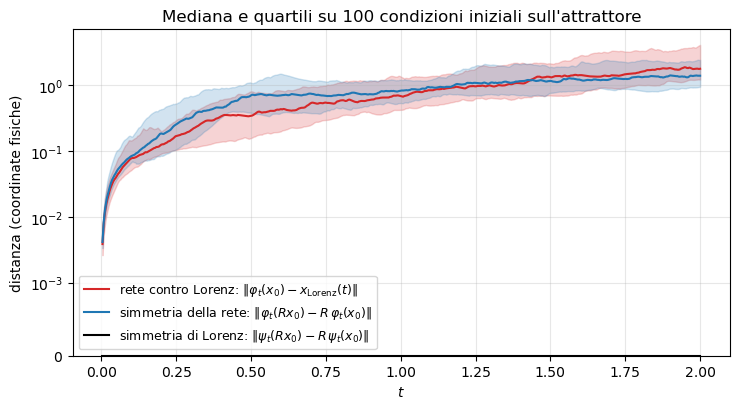

2) t = 0.5: mediana simmetria rete 0.700 | mediana rete-Lorenz 0.342 | simmetria Lorenz (massimo) 0.0e+00
2) t = 1.0: mediana simmetria rete 0.823 | mediana rete-Lorenz 0.682 | simmetria Lorenz (massimo) 0.0e+00
2) t = 2.0: mediana simmetria rete 1.390 | mediana rete-Lorenz 1.774 | simmetria Lorenz (massimo) 0.0e+00
3) 5 traiettorie lunghe (1000 u.t.), dalle stesse condizioni iniziali dello spettro
   Lorenz : frazione di tempo con x > 0 = 0.503 ± 0.009 | media di x = +0.05 ± 0.15 | media di y = +0.05 ± 0.15
   rete   : frazione di tempo con x > 0 = 0.515 ± 0.008 | media di x = +0.26 ± 0.12 | media di y = +0.21 ± 0.13


In [111]:
# ---------- simmetria di Lorenz: R(x, y, z) = (-x, -y, z)
R = np.diag([-1.0, -1.0, 1.0])

def F_rete(x):
    # campo della rete in coordinate fisiche: dx/dt = S f(S^-1 (x - m)), con S = diag(std) e m la media
    return std_ck * f_rete((x - mean_ck) / std_ck)

# punti sull'attrattore di Lorenz: traiettoria lunga, scartato il transitorio, un punto ogni 0.1 u.t.
x = np.array([1.0, 1.0, 1.0])
for _ in range(int(round(50 / DT_LYAP))):
    x = rk4_step(f_lorenz, x, DT_LYAP)
punti = []
for k in range(int(round(200 / DT_LYAP))):
    x = rk4_step(f_lorenz, x, DT_LYAP)
    if k % 10 == 0:
        punti.append(x)
punti = np.array(punti)

# ---------- 1) verifica sul campo: f(Rx) = R f(x)
Fx  = np.array([F_rete(p) for p in punti])                 # velocità della rete in x
FRx = np.array([F_rete(R @ p) for p in punti])             # velocità della rete in Rx
Fv  = np.array([f_lorenz(p) for p in punti])               # velocità vera in x
asimmetria = np.linalg.norm(FRx - Fx @ R, axis=1).mean() / np.linalg.norm(Fx, axis=1).mean()
err_campo  = np.linalg.norm(Fx - Fv, axis=1).mean() / np.linalg.norm(Fv, axis=1).mean()
asim_lorenz = np.abs(np.array([f_lorenz(R @ p) for p in punti]) - Fv @ R).max()
print(f'1) campo, su {len(punti)} punti dell\'attrattore')
print(f'   asimmetria della rete   <|f(Rx) - R f(x)|> / <|f(x)|> = {asimmetria:.2%}')
print(f'   errore del campo        <|f(x) - F(x)|> / <|F(x)|>    = {err_campo:.2%}   (riferimento)')
print(f'   Lorenz: max |F(Rx) - R F(x)| = {asim_lorenz:.1e}   (simmetria esatta)')

# ---------- 2) verifica sulle soluzioni: phi_t(R x0) = R phi_t(x0)
DT_SIM, T_SIM, N_CI_SIM = 0.004, 2.0, 100
n_passi = int(round(T_SIM / DT_SIM))
ci_sim = punti[np.random.default_rng(3).choice(len(punti), N_CI_SIM, replace=False)]
d_sim = np.zeros((N_CI_SIM, n_passi + 1))     # |phi_t(R x0) - R phi_t(x0)|   (rete contro rete riflessa)
d_vero = np.zeros((N_CI_SIM, n_passi + 1))    # |phi_t(x0) - x_Lorenz(t)|      (rete contro Lorenz, riferimento)
d_sim_L = np.zeros((N_CI_SIM, n_passi + 1))   # |psi_t(R x0) - R psi_t(x0)|   (stessa verifica per Lorenz vero)
for i, x0 in enumerate(ci_sim):
    a, b = x0.copy(), R @ x0                  # rete da x0 e da R x0
    c, e = x0.copy(), R @ x0                  # Lorenz vero da x0 e da R x0
    for n in range(1, n_passi + 1):
        a = rk4_step(F_rete, a, DT_SIM)
        b = rk4_step(F_rete, b, DT_SIM)
        c = rk4_step(f_lorenz, c, DT_SIM)
        e = rk4_step(f_lorenz, e, DT_SIM)
        d_sim[i, n] = np.linalg.norm(b - R @ a)
        d_vero[i, n] = np.linalg.norm(a - c)
        d_sim_L[i, n] = np.linalg.norm(e - R @ c)

t_sim = np.arange(n_passi + 1) * DT_SIM
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for d, nome, col in [(d_vero, r'rete contro Lorenz: $\|\varphi_t(x_0) - x_{\mathrm{Lorenz}}(t)\|$', 'tab:red'),
                     (d_sim, r'simmetria della rete: $\|\varphi_t(Rx_0) - R\,\varphi_t(x_0)\|$', 'tab:blue'),
                     (d_sim_L, r'simmetria di Lorenz: $\|\psi_t(Rx_0) - R\,\psi_t(x_0)\|$', 'black')]:
    q25, q50, q75 = np.percentile(d[:, 1:], [25, 50, 75], axis=0)
    ax.plot(t_sim[1:], q50, color=col, label=nome)
    ax.fill_between(t_sim[1:], q25, q75, color=col, alpha=0.2)
ax.set_yscale('symlog', linthresh=1e-3)       # scala logaritmica sopra 1e-3, lineare vicino a 0: mostra anche lo zero di Lorenz
ax.set_ylim(bottom=0)
ax.set_xlabel('$t$'); ax.set_ylabel('distanza (coordinate fisiche)')
ax.set_title(f'Mediana e quartili su {N_CI_SIM} condizioni iniziali sull\'attrattore')
ax.legend(fontsize=9); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()
for tt in (0.5, 1.0, 2.0):
    n = int(round(tt / DT_SIM))
    print(f'2) t = {tt:.1f}: mediana simmetria rete {np.median(d_sim[:, n]):.3f} | mediana rete-Lorenz {np.median(d_vero[:, n]):.3f} | '
          f'simmetria Lorenz (massimo) {d_sim_L[:, n].max():.1e}')

# ---------- 3) verifica statistica: i due lobi devono essere visitati allo stesso modo
T_LUNGO = 1000.0
def statistiche(f, x0):
    # frazione di tempo con x > 0 e medie di x e y lungo una traiettoria lunga (dopo il transitorio)
    x = np.array(x0, dtype=float)
    for _ in range(int(round(50 / DT_LYAP))):
        x = rk4_step(f, x, DT_LYAP)
    X = np.empty((int(round(T_LUNGO / DT_LYAP)), 3))
    for k in range(len(X)):
        x = rk4_step(f, x, DT_LYAP)
        X[k] = x
    return (X[:, 0] > 0).mean(), X[:, 0].mean(), X[:, 1].mean()

print(f'3) {len(ci)} traiettorie lunghe ({T_LUNGO:.0f} u.t.), dalle stesse condizioni iniziali dello spettro')
for nome, f in [('Lorenz', f_lorenz), ('rete', F_rete)]:
    r = np.array([statistiche(f, x0) for x0 in ci])
    m, s = r.mean(axis=0), r.std(axis=0, ddof=1)
    print(f'   {nome:7s}: frazione di tempo con x > 0 = {m[0]:.3f} ± {s[0]:.3f} | '
          f'media di x = {m[1]:+.2f} ± {s[1]:.2f} | media di y = {m[2]:+.2f} ± {s[2]:.2f}')

---
## Robustezza rispetto al seme della rete

Tutti i risultati precedenti vengono da **una sola** rete, addestrata con `SEED_RETE`. Il seme fissa due componenti casuali dell'addestramento: i pesi iniziali e l'ordine dei batch. Per capire se i risultati sono una proprietà del metodo o di quel particolare addestramento, si ripete l'addestramento finale con `len(SEMI)` semi diversi, lasciando fisso tutto il resto:

- stessi dati (le 23 traiettorie non di test) e stessa normalizzazione;
- stessi iperparametri: `LAMBDA_DIV` ed `EPOCHE_FINALI` scelti dalla k-fold, che **non** viene ripetuta per ogni seme;
- stesse condizioni iniziali per lo spettro (`ci`) e stesso metodo di calcolo.

Per ogni rete si calcolano la MAE di test, lo spettro di Lyapunov (media sulle `M_CI` condizioni iniziali), la divergenza media sull'attrattore, $D_{KY}$, $t_L$, la frazione di tempo con $x>0$ e lo scarto dalla curva di Lorenz nella mappa dei massimi. Il riepilogo riporta media e deviazione standard **tra i semi**.

Nella tabella compaiono due incertezze diverse:
- la dispersione **tra condizioni iniziali**, dentro una stessa rete, che misura il rumore numerico del calcolo dello spettro;
- la dispersione **tra semi**, che misura quanto il risultato dipende dall'addestramento.

Un errore rispetto a Lorenz che resta dello stesso segno ed è più grande della dispersione tra semi è sistematico; se cambia segno da un seme all'altro è dovuto all'addestramento.

Il primo seme della lista coincide con `SEED_RETE`: la sua rete deve riprodurre esattamente quella dell'addestramento principale, ed è un controllo che la procedura sia la stessa.

**Uso.** Con `ESEGUI_SEMI = True` si cancellano i risultati precedenti in `CARTELLA_SEMI` e si rifà tutto (circa 10 minuti per seme). Con `False` la cella di riepilogo rilegge i risultati salvati. I modelli addestrati si salvano in `CARTELLA_SEMI`, uno per seme, e non sovrascrivono `MODEL_PATH`.

In [112]:
# ---------- robustezza rispetto al seme della rete: addestramento e analisi per ogni seme
ESEGUI_SEMI = True                        # True: cancella i risultati precedenti e rifà tutto (circa 10 min per seme)
SEMI = [SEED_RETE, 46, 47, 48, 49]        # il primo coincide con l'addestramento principale (controllo)
CARTELLA_SEMI = 'robustezza_semi'
LAMBDA_SEMI = LAMBDA_DIV                  # scelto dalla k-fold
EPOCHE_SEMI = globals().get('EPOCHE_FINALI') or EPOCHS
FILE_SEMI = os.path.join(CARTELLA_SEMI, 'risultati_semi.csv')
CAMPI_SEMI = ['seme', 'test_mae', 'test_mse', 'mu1', 'mu2', 'mu3', 'mu1_sd_ci', 'mu3_sd_ci',
              'somma', 'div_media', 'dky', 't_L', 'frazione_x_pos', 'scarto_mappa', 'secondi']

def addestra_seme(seme):
    # stessa procedura dell'addestramento finale (23 traiettorie, lambda costante, ultima epoca); cambia solo il seme
    torch.manual_seed(seme)
    f = ODEFunc(HIDDEN_DIM).to(device)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(torch.cat([train_seq, val_seq])),
                                         batch_size=BATCH_SIZE, shuffle=True)
    opt = optim.Adam(f.parameters(), lr=LR)
    for epoch in range(1, EPOCHE_SEMI + 1):
        f.train()
        for (batch,) in loader:
            opt.zero_grad()
            mae = batch_loss(f, batch, t_seq, adjoint=ADJOINT)
            div = divergenza(f, batch[:, ::max(1, SEQ_LENGTH // 10), :].reshape(-1, 3))
            pen = (((div - DIV_TARGET) / DIV_TARGET) ** 2).mean()
            l2 = sum(p.pow(2).sum() for p in f.parameters())
            (mae + LAMBDA_SEMI * pen + L2_LAMBDA * l2).backward()
            opt.step()
    f.eval()
    return f

def campo_numpy(f):
    # campo e jacobiana della rete in NumPy (float64), come per la rete principale
    s_ = [('lin', l.weight.detach().double().cpu().numpy(), l.bias.detach().double().cpu().numpy())
          if isinstance(l, nn.Linear) else ('tanh', None, None) for l in f.net]
    def F(z):
        a = z
        for tipo, W, b in s_:
            a = W @ a + b if tipo == 'lin' else np.tanh(a)
        return a
    def J(z):
        a, Jm = z, np.eye(len(z))
        for tipo, W, b in s_:
            if tipo == 'lin':
                a, Jm = W @ a + b, W @ Jm
            else:
                a = np.tanh(a)
                Jm = (1.0 - a**2)[:, None] * Jm
        return Jm
    return F, J

def analizza_rete(f):
    # MAE di test, spettro, divergenza media, frazione di tempo con x > 0, scarto dalla curva di Lorenz
    test_mae_s, test_mse_s = evaluate(f, test_seq, t_seq)
    F, J = campo_numpy(f)
    F_fis = lambda x: std * F((x - mean) / std)                     # campo in coordinate fisiche
    ris = [spettro_lyapunov(F, J, (x0 - mean) / std, DT_LYAP, T_TRANS_LYAP, T_LYAP, seed=k)
           for k, x0 in enumerate(ci)]
    lam = np.array([r['lam'] for r in ris])
    mu = lam.mean(0)
    frazione = np.mean([statistiche(F_fis, x0)[0] for x0 in ci])
    scarto = np.nan
    if 'g_L' in globals():                                         # se la cella della mappa di Lorenz è stata eseguita
        zn_s, zn1_s = mappa(F_fis)
        dentro_s = (zn_s >= zn_L.min()) & (zn_s <= zn_L.max())
        scarto = np.abs(zn1_s[dentro_s] - g_L(zn_s[dentro_s])).mean() if dentro_s.any() else np.nan
    return dict(test_mae=test_mae_s, test_mse=test_mse_s, mu1=mu[0], mu2=mu[1], mu3=mu[2],
                mu1_sd_ci=lam[:, 0].std(), mu3_sd_ci=lam[:, 2].std(), somma=mu.sum(),
                div_media=np.mean([r['traccia'] for r in ris]), dky=kaplan_yorke(mu),
                t_L=1 / mu[0] if mu[0] > 0 else np.nan, frazione_x_pos=frazione, scarto_mappa=scarto)

if ESEGUI_SEMI:
    os.makedirs(CARTELLA_SEMI, exist_ok=True)
    vecchi = glob.glob(os.path.join(CARTELLA_SEMI, '*.csv')) + glob.glob(os.path.join(CARTELLA_SEMI, '*.pt'))
    for nome in vecchi:
        os.remove(nome)
    print(f'cancellati {len(vecchi)} file precedenti in {CARTELLA_SEMI!r}')
    print(f'{len(SEMI)} semi, LAMBDA_DIV = {LAMBDA_SEMI:g}, {EPOCHE_SEMI} epoche')
    t_start = time.time()
    for seme in SEMI:
        t0 = time.time()
        f_s = addestra_seme(seme)
        torch.save({'state_dict': f_s.state_dict(), 'mean': mean, 'std': std, 'hidden_dim': HIDDEN_DIM,
                    'seed_rete': seme, 'lambda_div': LAMBDA_SEMI, 'epoch': EPOCHE_SEMI},
                   os.path.join(CARTELLA_SEMI, f'modello_seme_{seme}.pt'))
        r = analizza_rete(f_s)
        r.update(seme=seme, secondi=round(time.time() - t0))
        nuovo = not os.path.exists(FILE_SEMI)
        with open(FILE_SEMI, 'a', newline='') as fh:                # una riga per seme, appena è pronta
            w = csv.DictWriter(fh, fieldnames=CAMPI_SEMI)
            if nuovo:
                w.writeheader()
            w.writerow({k: r[k] for k in CAMPI_SEMI})
        print(f'seme {seme}: test MAE {r["test_mae"]:.5f} | mu = ({r["mu1"]:.4f}, {r["mu2"]:.4f}, {r["mu3"]:.4f}) | '
              f'<div> {r["div_media"]:.3f} | x>0 {r["frazione_x_pos"]:.3f} | {r["secondi"]}s')
    print(f'completato in {(time.time() - t_start) / 60:.1f} minuti')
else:
    print('ESEGUI_SEMI = False: si usano i risultati già salvati in', CARTELLA_SEMI)

cancellati 6 file precedenti in 'robustezza_semi'
5 semi, LAMBDA_DIV = 1.3, 80 epoche
seme 45: test MAE 0.00891 | mu = (0.8904, -0.0005, -14.5577) | <div> -13.668 | x>0 0.515 | 652s
seme 46: test MAE 0.01154 | mu = (0.8853, -0.0006, -14.5693) | <div> -13.685 | x>0 0.554 | 791s
seme 47: test MAE 0.00702 | mu = (0.8788, -0.0011, -14.4946) | <div> -13.617 | x>0 0.574 | 841s
seme 48: test MAE 0.00953 | mu = (0.8733, 0.0003, -14.5763) | <div> -13.703 | x>0 0.569 | 901s
seme 49: test MAE 0.01391 | mu = (0.8862, 0.0003, -14.5679) | <div> -13.681 | x>0 0.531 | 687s
completato in 64.5 minuti


  seme    MAE di test           mu_1           mu_2           mu_3        <div f>           D_KY            t_L frazione x > 0   scarto mappa
    45        0.00891         0.8904        -0.0005       -14.5577        -13.668         2.0611          1.123          0.515          0.405
    46        0.01154         0.8853        -0.0006       -14.5693        -13.685         2.0607          1.130          0.554          0.330
    47        0.00702         0.8788        -0.0011       -14.4946        -13.617         2.0605          1.138          0.574          0.272
    48        0.00953         0.8733         0.0003       -14.5763        -13.703         2.0599          1.145          0.569          0.277
    49        0.01391         0.8862         0.0003       -14.5679        -13.681         2.0609          1.128          0.531          0.414
----------------------------------------------------------------------------------------------------------------------------------------------
 medi

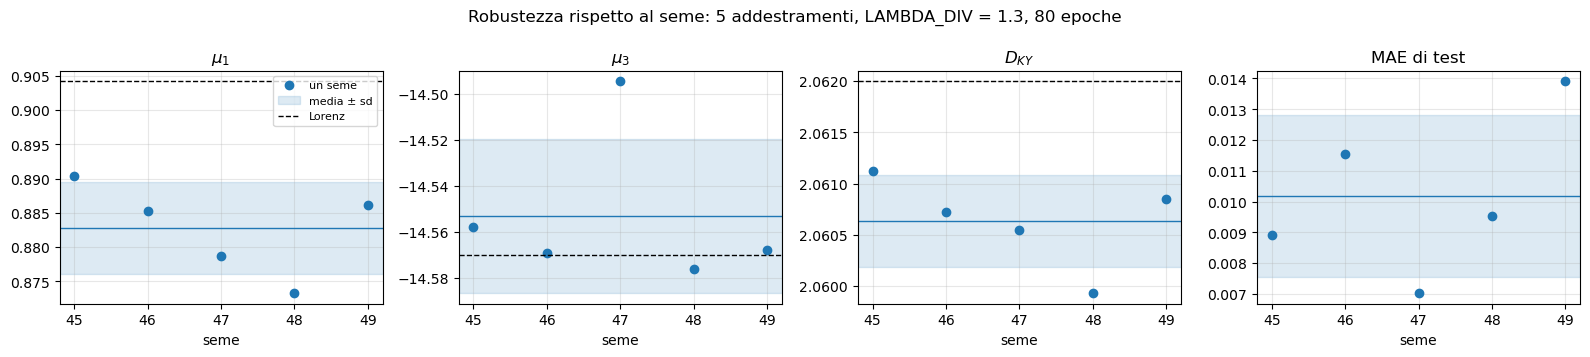

In [113]:
# ---------- riepilogo: media e deviazione standard tra i semi, confronto con Lorenz
with open(FILE_SEMI) as fh:
    tab = [{k: float(v) for k, v in r.items()} for r in csv.DictReader(fh)]
col = lambda k: np.array([r[k] for r in tab])
mu_L = lam_L.mean(0)
rif = {'mu1': mu_L[0], 'mu2': mu_L[1], 'mu3': mu_L[2], 'div_media': DIV_TARGET,
       'dky': kaplan_yorke(mu_L), 't_L': 1 / mu_L[0], 'frazione_x_pos': 0.5}

voci = [('test_mae', 'MAE di test', '.5f'), ('mu1', 'mu_1', '.4f'), ('mu2', 'mu_2', '.4f'), ('mu3', 'mu_3', '.4f'),
        ('div_media', '<div f>', '.3f'), ('dky', 'D_KY', '.4f'), ('t_L', 't_L', '.3f'),
        ('frazione_x_pos', 'frazione x > 0', '.3f'), ('scarto_mappa', 'scarto mappa', '.3f')]

print(f'{"seme":>6} ' + ' '.join(f'{nome:>14}' for _, nome, _ in voci))
for r in tab:
    print(f'{int(r["seme"]):>6} ' + ' '.join(f'{r[k]:>14{fm}}' for k, _, fm in voci))
print('-' * (7 + 15 * len(voci)))
print(f'{"media":>6} ' + ' '.join(f'{col(k).mean():>14{fm}}' for k, _, fm in voci))
print(f'{"sd":>6} ' + ' '.join(f'{col(k).std(ddof=1):>14{fm}}' for k, _, fm in voci))
print(f'{"Lorenz":>6} ' + ' '.join(f'{rif[k]:>14{fm}}' if k in rif else f'{"-":>14}' for k, _, fm in voci))

print(f'\nerrore rispetto a Lorenz (media tra i semi ± sd tra i semi), {len(tab)} semi:')
for k, nome in [('mu1', 'mu_1'), ('mu3', 'mu_3'), ('div_media', '<div f>'), ('dky', 'D_KY')]:
    e = (col(k) - rif[k]) / abs(rif[k])
    print(f'  {nome:8s} {e.mean():+.2%} ± {e.std(ddof=1):.2%}   (segno costante: {"sì" if np.all(e > 0) or np.all(e < 0) else "no"})')
e_fr = (col('dky') - 2) / (rif['dky'] - 2) - 1                    # D_KY - 2: il 2 dominerebbe l'errore relativo
print(f'  D_KY - 2 {e_fr.mean():+.2%} ± {e_fr.std(ddof=1):.2%}   (parte frazionaria)')
print(f'\ndispersione di mu_1: tra i semi {col("mu1").std(ddof=1):.4f} | tra condizioni iniziali (media sui semi) {col("mu1_sd_ci").mean():.4f}')
print(f'dispersione di mu_3: tra i semi {col("mu3").std(ddof=1):.4f} | tra condizioni iniziali (media sui semi) {col("mu3_sd_ci").mean():.4f}')

fig, axs = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (k, nome) in zip(axs, [('mu1', r'$\mu_1$'), ('mu3', r'$\mu_3$'), ('dky', r'$D_{KY}$'), ('test_mae', 'MAE di test')]):
    v = col(k)
    ax.plot(np.arange(len(v)), v, 'o', color='tab:blue', label='un seme')
    ax.axhline(v.mean(), color='tab:blue', lw=1)
    ax.axhspan(v.mean() - v.std(ddof=1), v.mean() + v.std(ddof=1), color='tab:blue', alpha=0.15, label='media ± sd')
    if k in rif:
        ax.axhline(rif[k], color='black', ls='--', lw=1, label='Lorenz')
    ax.set_xticks(range(len(v))); ax.set_xticklabels([int(s) for s in col('seme')])
    ax.set_xlabel('seme'); ax.set_title(nome); ax.grid(True, alpha=0.3)
axs[0].legend(fontsize=8)
plt.suptitle(f'Robustezza rispetto al seme: {len(tab)} addestramenti, LAMBDA_DIV = {LAMBDA_SEMI:g}, {EPOCHE_SEMI} epoche')
plt.tight_layout(); plt.show()